# شبکه‌های عصبی و پس‌انتشار

**محمود امین‌طوسی، پاییز ۱۴۰۵**

گروه علوم کامپیوتر، دانشگاه فردوسی مشهد

نسخهٔ اول این درس بر پایهٔ [درس تاماس بیوزن](https://ubc-mds.github.io/DSCI_572_sup-learn-2) نوشته شده بود؛ این نسخه همان مطالب را نگه می‌دارد و آن‌ها را در قالب یک روایت پیوسته بازآرایی می‌کند.

<div class="langswitch">
  <a href="#lang-en">English</a> · <strong>فارسی</strong>
</div>


## نقشهٔ این جلسه

می‌دانیم چگونه یک خط راست را به داده برازش دهیم و چگونه گرادیان کاهشی پارامترهایش را پیدا می‌کند
([رگرسیون خطی، بخش ۲](Linear-Regression-Part2.ipynb)). امروز همان ماشین‌آلات را نگه می‌داریم و هر بار
فقط یک چیز را عوض می‌کنیم:

1. **نرون**: یک مدل خطی به‌علاوهٔ یک *تابع فعال‌سازی* غیرخطی (بخش ۱).
2. **سیگموید**: چرا دسته‌بندی به آن نیاز دارد، مشتقش چیست، و یک نرون که یک احتمال را یاد می‌گیرد
   (بخش‌های ۲ و ۳).
3. **دو نرون**: یک سیگموید منحنی را یک بار خم می‌کند؛ منحنی‌ای که بالا *و* پایین می‌رود به دو نرون
   نیاز دارد (بخش ۴).
4. **پرسپترون**: نرون اصلی روزنبلات، دروازهٔ AND که حلش می‌کند، و XOR که نمی‌تواند (بخش ۵).
5. **پس‌انتشار**: اینکه خطا چگونه به عقب در شبکه پس داده می‌شود، یک بار دستی و یک بار با `torch`
   (بخش ۶).
6. **شبکه‌ها**: لایه‌های پنهان، ماژول‌های PyTorch، و یک مسئلهٔ واقعی دسته‌بندی (بخش‌های ۷ تا ۹).


## هدف‌های یادگیری درس

در پایان این جلسه باید بتوانید

- یک نرون را به شکل $a=\varphi(\mathbf w^\top\mathbf x+b)$ بنویسید و بگویید تابع فعال‌سازی چه می‌کند؛
- رابطهٔ $\sigma'(z)=\sigma(z)\big(1-\sigma(z)\big)$ را استنتاج کنید و در یک گام گرادیان به کار ببرید؛
- توضیح دهید چرا یک نرون فقط یک مرز خطی می‌کشد، آن را روی AND نشان دهید و ثابت کنید که روی XOR شکست
  می‌خورد؛
- قاعدهٔ زنجیره‌ای را به عقب در یک شبکهٔ دولایه دنبال کنید و نتیجه را با `backward()` بررسی کنید؛
- یک شبکهٔ کوچک در PyTorch برای رگرسیون و برای دسته‌بندی بسازید و آموزش دهید.


In [1]:
# Auto-setup when running on Google Colab
import os
if 'google.colab' in str(get_ipython()) and not os.path.exists('/content/machine-learning'):
    !git clone -q https://github.com/fum-cs/machine-learning.git /content/machine-learning
    %cd machine-learning/notebooks

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression, make_circles, make_blobs
from sklearn.linear_model import LinearRegression
from torchsummary import summary

from utils.plotting import *

In [3]:
def trainer(model, criterion, optimizer, X, y, epochs=100, batch_size=None, verbose=False):
    '''The training loop of the whole lecture: predict, loss, backward, step.'''
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size or len(X), shuffle=True)
    for epoch in range(epochs):
        total = 0.0
        for xb, yb in loader:
            optimizer.zero_grad()            # 1. forget the gradients of the previous batch
            loss = criterion(model(xb), yb)  # 2. forward pass, then the loss
            loss.backward()                  # 3. backward pass: the chain rule, backwards
            optimizer.step()                 # 4. move the parameters against the gradient
            total += loss.item()
        if verbose and (epoch + 1) % 200 == 0:
            print(f"epoch {epoch + 1:4d}   loss {total / len(loader):.4f}")
    return total / len(loader)


def fit(model, x, y, lr=0.1, epochs=1000, **kwargs):
    '''Train a regression model on the whole data set and return the final MSE.'''
    return trainer(model, nn.MSELoss(), torch.optim.SGD(model.parameters(), lr=lr),
                   x, y, epochs=epochs, **kwargs)


def plot_1d(x, y, curves=(), names=(), xlabel="x", ylabel="y"):
    '''Scatter of one-dimensional data, plus any number of curves (used for the 1-D examples).'''
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.scatter(np.ravel(x), np.ravel(y), s=22, alpha=0.55, color="tab:blue")
    for (cx, cy), name in zip(curves, names):
        ax.plot(np.ravel(cx), np.ravel(cy), lw=2.6, label=name)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if names:
        ax.legend(frameon=False)
    return fig

## ۱. کجاییم: یک خط از قبل یک نرون است

جلسهٔ قبل با یک خط راست که با گرادیان کاهشی برازش شده بود تمام شد،

$$\hat y = w_0 + w_1x = \mathbf w^\top\mathbf x, \qquad x_0=1,$$

و با به‌روزرسانی $w_j \leftarrow w_j - \eta\,\partial \text{MSE}/\partial w_j$ که تا زمانی تکرار
می‌شد که خطا دیگر پایین نیاید.


last lecture's answer:  y = 1.03 + 1.93 x


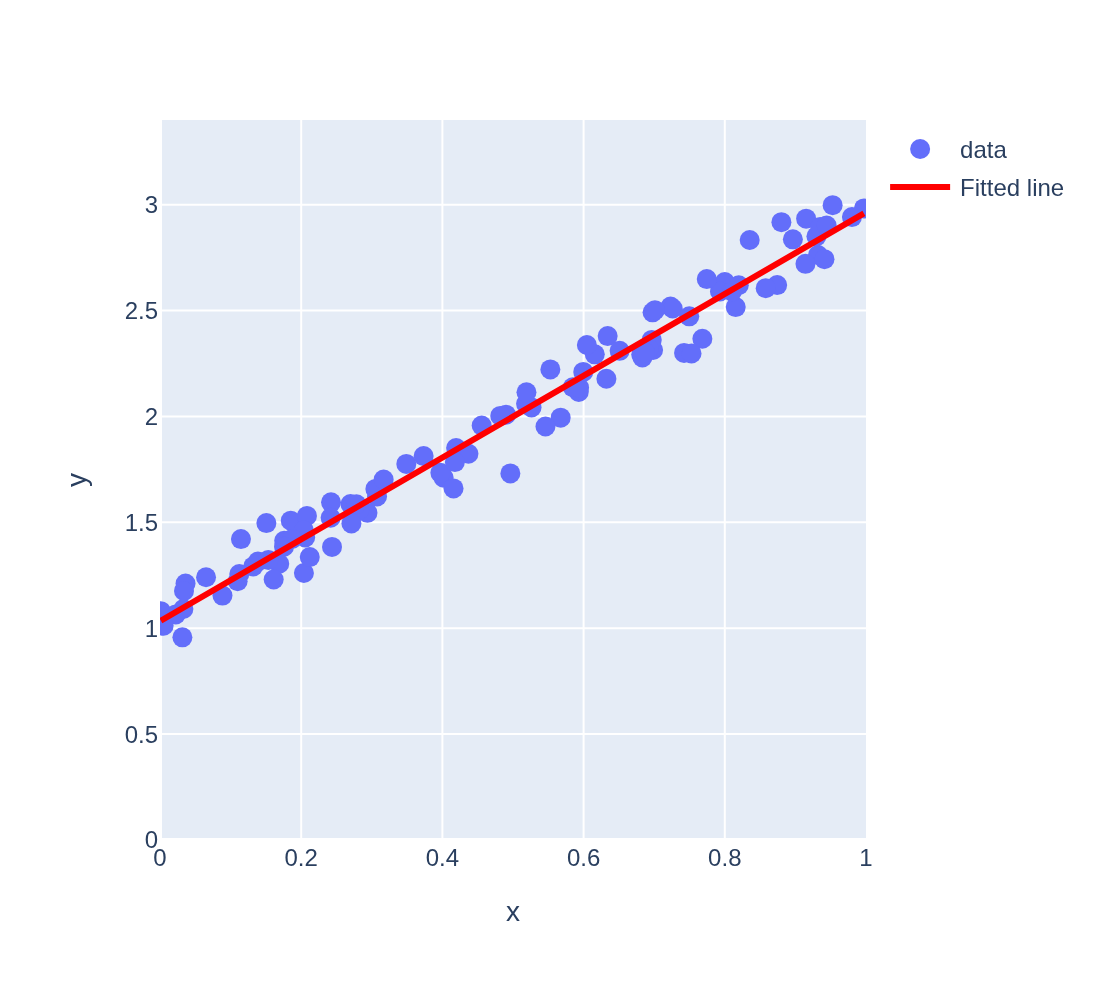

In [4]:
torch.manual_seed(0)
x_line = torch.rand(100, 1)
y_line = 1 + 2 * x_line + 0.1 * torch.randn(100, 1)
line = LinearRegression().fit(x_line.numpy(), y_line.numpy())
print(f"last lecture's answer:  y = {np.ravel(line.intercept_)[0]:.2f} + {np.ravel(line.coef_)[0]:.2f} x")
plot_regression(x_line.numpy().ravel(), y_line.numpy().ravel(), line.predict(x_line.numpy()).ravel(),
                x_range=[0, 1], y_range=[0, 3.4], dx=0.2, dy=0.5)

هر شبکه‌ای در این درس از همان شیء ساخته می‌شود، با یک اضافه:

$$z = \mathbf w^\top\mathbf x + b, \qquad a = \varphi(z)$$

$z$ **پیش‌فعال‌سازی** است (یک مدل خطی)، $\varphi$ یک **تابع فعال‌سازی** غیرخطی و ثابت است، و $a$
خروجی نرون. پس یک نرون یعنی *یک جمع وزنی، و بعد یک فشرده‌سازی*:

| فعال‌سازی | نرون | کاربرد |
|---|---|---|
| $\varphi(z)=z$ | $\mathbf w^\top\mathbf x+b$ | رگرسیون خطی (جلسهٔ قبل) |
| $\varphi(z)=\sigma(z)$ | عددی در $(0,1)$ | احتمال یک کلاس، و بلوک سازندهٔ شبکه‌ها |
| $\varphi(z)=\mathbf 1[z\geq 0]$ | $0$ یا $1$ | پرسپترون روزنبلات: یک تصمیم سخت |

- با فعال‌سازی همانی، نرون **همان** چیزی است که هفتهٔ قبل برازش کردیم؛ چیز تازه‌ای نیست.
- همهٔ نکتهٔ جالب در $\varphi$ است. بخش بعد دربارهٔ سیگموید است: انتخابی که دسته‌بندی را ممکن می‌کند
  — و چون مشتق مرتبی دارد، آموزش را هم ممکن می‌کند.

از اینجا به بعد کد با تنسورهای `torch` نوشته می‌شود که برای هر کاری که می‌کنیم (حساب، اندیس‌گذاری،
`@`) مثل آرایه‌های NumPy رفتار می‌کنند. دلیل استفاده از آن‌ها آخرین خط حلقه در بخش ۶ است:
`loss.backward()` به عملیاتی نیاز دارد که ثبت شده باشند، و فقط تنسورها این کار را می‌کنند.


## ۲. سیگموید و مشتقش

یک دسته‌بند به مدلی نیاز دارد که خروجی‌اش را بتوان احتمال خواند، $0\le \hat y\le 1$، و گرادیان
کاهشی به مدلی نیاز دارد که مشتق‌پذیر باشد. شرط اول خط راست را کنار می‌گذارد، چون روی تمام
$\mathbb R$ کشیده می‌شود؛ شرط دوم پلهٔ سخت را. هر دو شرط با یک تابع برآورده می‌شوند:

$$\sigma(z)=\frac{1}{1+e^{-z}}$$


- **بازه.** $\sigma(z)\in(0,1)$، با $\sigma(0)=\tfrac12$، $\sigma(z)\to1$ وقتی $z\to\infty$ و
  $\sigma(z)\to0$ وقتی $z\to-\infty$.
- **یکنوا.** هر امتیاز بزرگ‌تر $z$ همیشه یعنی احتمال بزرگ‌تر — خروجی نسخهٔ نرم‌شدهٔ پلهٔ
  $\mathbf 1[z\ge 0]$ است.
- **تقارن.** $\sigma(-z)=1-\sigma(z)$، پس دو کلاس به یک شکل رفتار می‌شوند.
- **هموار.** همه‌جا مشتق دارد، چیزی که پله ندارد.


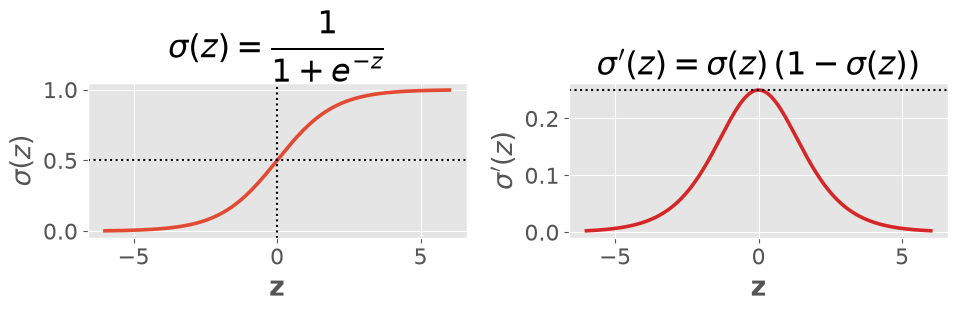

In [5]:
z = np.linspace(-6, 6, 400)
s = 1 / (1 + np.exp(-z))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(z, s, lw=2.6)
axes[0].axhline(0.5, ls=':', c='k')
axes[0].axvline(0, ls=':', c='k')
axes[0].set_title(r'$\sigma(z)=\dfrac{1}{1+e^{-z}}$')
axes[0].set_xlabel('z')
axes[0].set_ylabel(r'$\sigma(z)$')

axes[1].plot(z, s * (1 - s), lw=2.6, color='tab:red')
axes[1].axhline(0.25, ls=':', c='k')
axes[1].set_title(r"$\sigma'(z)=\sigma(z)\,(1-\sigma(z))$")
axes[1].set_xlabel('z')
axes[1].set_ylabel(r"$\sigma'(z)$")
plt.tight_layout();

### استنتاج مشتق

سیگموید را به شکل توان بنویسید و با قاعدهٔ زنجیره‌ای مشتق بگیرید:

$$\begin{aligned}
\sigma(z) &= \left(1+e^{-z}\right)^{-1}\\
\sigma'(z) &= -\left(1+e^{-z}\right)^{-2}\cdot\left(-e^{-z}\right)
           = \frac{e^{-z}}{\left(1+e^{-z}\right)^{2}}
\end{aligned}$$

نتیجه را می‌توان با خود $\sigma$ نوشت — مربع را به دو تکه بشکنید:

$$\frac{e^{-z}}{\left(1+e^{-z}\right)^{2}}
= \underbrace{\frac{1}{1+e^{-z}}}_{\sigma(z)}\cdot\underbrace{\frac{e^{-z}}{1+e^{-z}}}_{1-\sigma(z)}
\qquad\Longrightarrow\qquad
\boxed{\;\sigma'(z)=\sigma(z)\big(1-\sigma(z)\big)\;}$$

**مشتق تابعی از خروجی است، نه از ورودی.** اگر گذر رو به جلو $a=\sigma(z)$ را ذخیره کند، گذر رو به
عقب فقط یک تفریق و یک ضرب هزینه دارد — بدون نمایی دوم. به همین دلیل سیگموید دهه‌ها نرون استاندارد بود،
و همان حقهٔ «از مقدار رو به جلو استفاده کن» زیربنای هر فعال‌سازی در بخش ۸ است.

دو نتیجهٔ آن که ارزش یادداشت دارند:

- شیب در $z=0$ بیشترین مقدار است، جایی که $\sigma'(0)=\tfrac14$. هرگز از $0.25$ بیشتر نمی‌شود.
- دور از صفر منحنی صاف است و $\sigma'\to0$: نرونی که خیلی مطمئن است تقریباً یاد نمی‌گیرد. این همان
  مسئلهٔ **محو شدن گرادیان** است و دلیل آنکه لایه‌های پنهان امروزی معمولاً از ReLU استفاده می‌کنند.

این استنتاج آن‌قدر کوتاه است که می‌توان عددی بررسی‌اش کرد:


In [6]:
z = torch.tensor([-3.0, -1.0, 0.0, 1.0, 3.0], requires_grad=True)
s = torch.sigmoid(z)
s.sum().backward()

print("from the formula :", (s * (1 - s)).detach().numpy().round(4))
print("from autograd    :", z.grad.numpy().round(4))

from the formula : [0.0452 0.1966 0.25   0.1966 0.0452]
from autograd    : [0.0452 0.1966 0.25   0.1966 0.0452]


### معنای هندسی این حرف

چون $\sigma$ یکنواست، تصمیم «$\sigma(z)>0.5$» همان تصمیم «$z>0$» است. پس یک نرون سیگموید
**یک دسته‌بند خطی با خروجی احتمالاتی** است: مرز $\mathbf w^\top\mathbf x+b=0$ یک خط است (در ابعاد
بالاتر یک ابرصفحه). همین یک واقعیت چیزی است که XOR در بخش ۵ می‌شکند.


## ۳. یک نرون سیگموید یک احتمال را یاد می‌گیرد

یک مسئلهٔ دسته‌بندی یک‌بعدی بچینید: ساعت‌های مطالعه در برابر قبولی در امتحان، با دو کلاسی که کمی هم
هم‌پوشانی دارند.


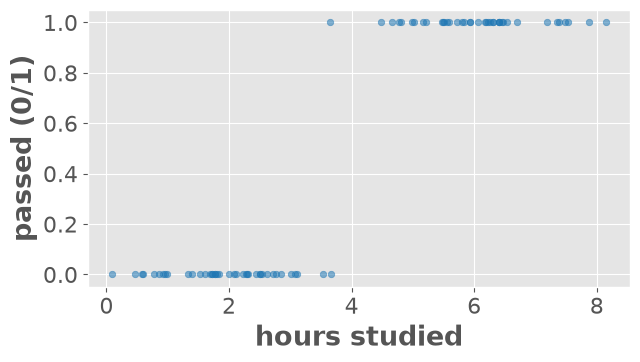

In [7]:
torch.manual_seed(0)
n = 40
X_cls = torch.cat([2.0 + 0.9 * torch.randn(n, 1), 6.0 + 0.9 * torch.randn(n, 1)])
y_cls = torch.cat([torch.zeros(n, 1), torch.ones(n, 1)])
plot_1d(X_cls, y_cls, xlabel="hours studied", ylabel="passed (0/1)");

مدل همان نرون بخش ۱ با $\varphi=\sigma$ است — دو پارامتر، و همین:

$$\hat y=\sigma(wx+b)$$

`nn.Linear(1,1)` مقدار $wx+b$ را حساب می‌کند و `nn.Sigmoid()` آن را می‌فشارد. تابع خطا همان خطای
مربعی هفتهٔ قبل است (هدف‌ها ۰ و ۱ هستند)؛ بخش ۹ آن را با تابع خطای درست دسته‌بندی عوض می‌کند.
`trainer()` همان حلقهٔ چهارخطی کل درس است — در بخش ۶ بازش می‌کنیم.


In [8]:
model = nn.Sequential(nn.Linear(1, 1), nn.Sigmoid())
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)
loss = trainer(model, nn.MSELoss(), optimizer, X_cls, y_cls, epochs=400, verbose=True)

w, b = [p.item() for p in model.parameters()]
accuracy = ((model(X_cls) > 0.5).float() == y_cls).float().mean().item()
print(f"\nw = {w:.2f}, b = {b:.2f}")
print(f"decision boundary  wx + b = 0  at  x = {-b / w:.2f} hours")
print(f"training accuracy: {accuracy:.0%}")

epoch  200   loss 0.0398
epoch  400   loss 0.0256

w = 1.18, b = -4.43
decision boundary  wx + b = 0  at  x = 3.76 hours
training accuracy: 99%


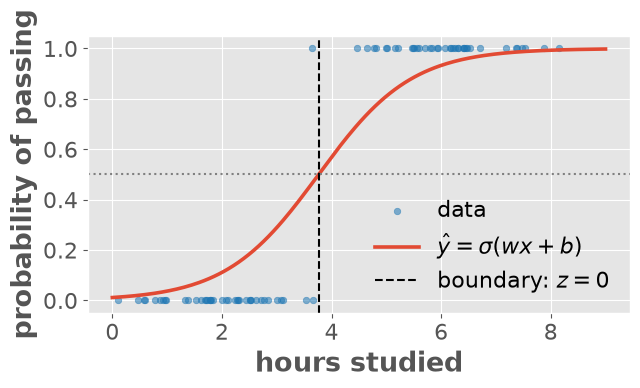

In [9]:
grid = torch.linspace(0, 9, 200).reshape(-1, 1)
with torch.no_grad():
    p = model(grid).numpy().ravel()

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(X_cls.numpy().ravel(), y_cls.numpy().ravel(), s=22, alpha=0.55, color="tab:blue", label="data")
ax.plot(grid.numpy().ravel(), p, lw=2.6, label=r"$\hat y=\sigma(wx+b)$")
ax.axvline(-b / w, ls='--', c='k', label="boundary: $z=0$")
ax.axhline(0.5, ls=':', c='gray')
ax.set_xlabel("hours studied")
ax.set_ylabel("probability of passing")
ax.legend(frameon=False);

نرون دو چیز را هم‌زمان یاد گرفت: **کجا** ببرد، از بایاس، و **چقدر تیز**، از وزن. برش یک نقطهٔ
واحد روی خط است و در دو بعد یک خط راست — مدل شکل دیگری در اختیار ندارد. این همان رگرسیون لجستیک است
که به شکل یک شبکهٔ یک‌نرونی کشیده شده.


## ۴. یک نرون یک بار خم می‌شود؛ دو نرون دو بار

سیگموید یکنواست، پس یک نرون تنها می‌تواند منحنی‌ای بسازد که بالا می‌رود (یا فقط پایین می‌آید). بسیاری
از منحنی‌ها کار دیگری می‌کنند. اینجا دو مجموعه‌دادهٔ کوچک داریم: یک منحنی S-شکل، و یک **برآمدگی** که
اول بالا می‌رود و بعد پایین می‌آید.


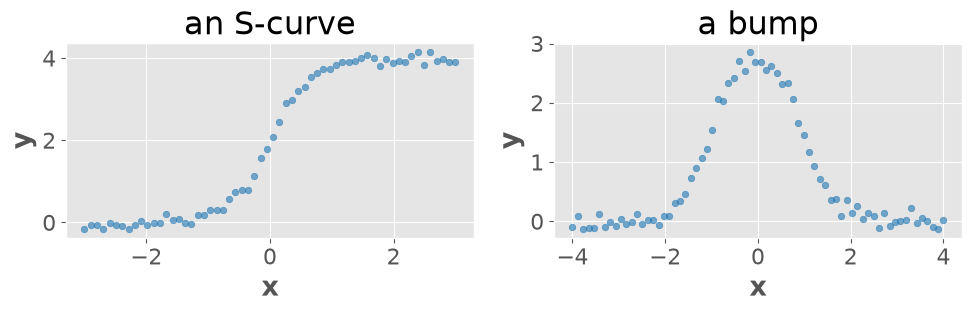

In [10]:
torch.manual_seed(1)
x_s = torch.linspace(-3, 3, 60).reshape(-1, 1)
y_s = 4 * torch.sigmoid(3 * x_s) + 0.1 * torch.randn(60, 1)

torch.manual_seed(2)
x_b = torch.linspace(-4, 4, 70).reshape(-1, 1)
y_b = 3 * torch.sigmoid(3 * (x_b + 1)) - 3 * torch.sigmoid(3 * (x_b - 1)) + 0.1 * torch.randn(70, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].scatter(x_s.numpy(), y_s.numpy(), s=22, alpha=0.6, color="tab:blue")
axes[0].set_title("an S-curve")
axes[1].scatter(x_b.numpy(), y_b.numpy(), s=22, alpha=0.6, color="tab:blue")
axes[1].set_title("a bump")
for ax in axes:
    ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout();

یک نرون سیگموید، با یک خوانش خطی تا بتواند به بازهٔ $y$ برسد:

$$\hat y = w_2\,\sigma(w_1x+b_1)+b_2 \qquad\text{(2 + 2 parameters)}$$

اول آن را به منحنی S برازش می‌کنیم.


loss: 0.0077
learnt model:  y = 4.02*sigmoid(3.02x +0.01) -0.03


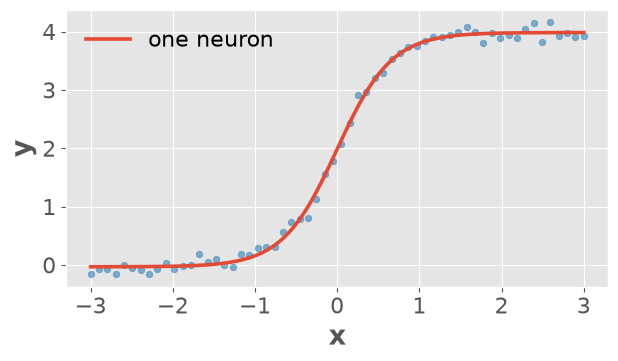

In [11]:
torch.manual_seed(0)
one_neuron = nn.Sequential(nn.Linear(1, 1), nn.Sigmoid(), nn.Linear(1, 1))
loss_s = fit(one_neuron, x_s, y_s, lr=0.1, epochs=3000)

xs = torch.linspace(-3, 3, 300).reshape(-1, 1)
with torch.no_grad():
    y_hat_s = one_neuron(xs).numpy()
print(f"loss: {loss_s:.4f}")

# the four numbers behind panel (a) of the figure below
w1, b1 = one_neuron[0].weight.item(), one_neuron[0].bias.item()
w2, b2 = one_neuron[2].weight.item(), one_neuron[2].bias.item()
print(f"learnt model:  y = {w2:.2f}*sigmoid({w1:.2f}x {b1:+.2f}) {b2:+.2f}")

plot_1d(x_s, y_s, curves=[(xs.numpy(), y_hat_s)], names=["one neuron"]);

### شکل مدل

![](img/nn-one-two.png)

- پنل (a) همان `one_neuron` است، مدل همین بخش: `Linear(1, 1)` → `Sigmoid` → `Linear(1, 1)`.
  چهار پارامتر، یکی برای هر فلش و یکی برای هر بایاس: $w_1,b_1$ به نرون پنهان، $w_2,b_2$ از آن بیرون.
- پنل (b) شبکهٔ بخش ۴ است: `Linear(1, 2)` → `Sigmoid` → `Linear(2, 1)`. شش پارامتر: همان جعبه با یک
  نرون بیشتر در میان. به شکل نگاه کنید نه به نام‌ها — هر فلش یک وزن است، هر نرون یک بایاس و یک
  فعال‌سازی با خود دارد.


خوب است. اما همان نرون روی برآمدگی نمی‌تواند بپیچد: هر مقداری که $w_1$ و $w_2$ داشته باشند،
منحنی یکنواست، در حالی که داده بالا می‌رود و بعد پایین می‌آید.


loss: 0.7716   (predicting the mean everywhere gives 0.9917)


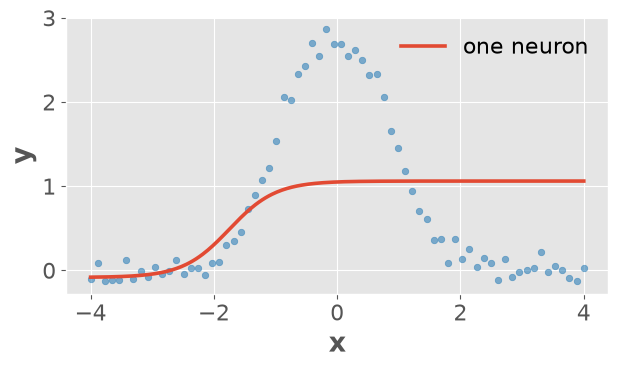

In [12]:
torch.manual_seed(0)
one_neuron_b = nn.Sequential(nn.Linear(1, 1), nn.Sigmoid(), nn.Linear(1, 1))
loss_one = fit(one_neuron_b, x_b, y_b, lr=0.1, epochs=3000)

xb = torch.linspace(-4, 4, 300).reshape(-1, 1)
with torch.no_grad():
    y_hat_one = one_neuron_b(xb).numpy()
print(f"loss: {loss_one:.4f}   (predicting the mean everywhere gives {y_b.var().item():.4f})")
plot_1d(x_b, y_b, curves=[(xb.numpy(), y_hat_one)], names=["one neuron"]);

حالا **یک نرون دیگر** به یک لایهٔ پنهان اضافه کنید. مدل می‌شود

$$\hat y = w_3\,\sigma(w_1x+b_1) + w_4\,\sigma(w_2x+b_2) + b_3 \qquad\text{(6 parameters)}$$

و در PyTorch فقط یک آرگومان اضافه است: `Linear(1, 2)` به‌جای `Linear(1, 1)`.


loss with two hidden neurons: 0.0078
learnt model:  y = 3.17*sigmoid(2.87x +2.92) -3.11*sigmoid(2.84x -2.66) -0.05


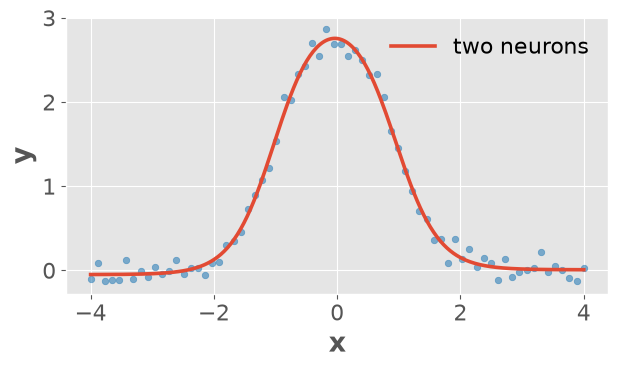

In [13]:
torch.manual_seed(0)
two_neurons = nn.Sequential(nn.Linear(1, 2), nn.Sigmoid(), nn.Linear(2, 1))
loss_two = fit(two_neurons, x_b, y_b, lr=0.2, epochs=4000)

with torch.no_grad():
    y_hat_two = two_neurons(xb).numpy()
print(f"loss with two hidden neurons: {loss_two:.4f}")

hidden, out = two_neurons[0], two_neurons[2]
(w1, w2), (b1, b2) = hidden.weight.detach().ravel().tolist(), hidden.bias.detach().tolist()
(w3, w4), b3 = out.weight.detach().ravel().tolist(), out.bias.item()
print(f"learnt model:  y = {w3:.2f}*sigmoid({w1:.2f}x {b1:+.2f}) {w4:+.2f}*sigmoid({w2:.2f}x {b2:+.2f}) {b3:+.2f}")

plot_1d(x_b, y_b, curves=[(xb.numpy(), y_hat_two)], names=["two neurons"]);

شبکه همان ساختاری را کشف کرد که ما دستی در داده ساخته بودیم: **دو پلهٔ لجستیک با علامت‌های
مخالف**. هر نرون پنهان یک پلهٔ بالا (یا یک پلهٔ پایین) می‌دهد و نرون خروجی آن‌ها را جمع می‌زند.

- برآمدگی تفاضل دو سیگموید است؛ سه نوسان نرون بیشتری می‌خواهد، و در حالت کلی لایهٔ پنهان یک
  **پایهٔ کوچکی از سیگمویدها** است که لایهٔ خروجی منحنی را از آن‌ها می‌سازد.
- گذار از یک نرون به دو نرون، از ۴ پارامتر و یک منحنی یکنوا به ۶ پارامتر و منحنی‌ای که می‌پیچد
  رسید. تمام ایدهٔ لایهٔ پنهان همین است: *نه فرمول شیک‌تر، بلکه نرون‌های بیشتر کنار هم، که هرکدام
  یک تکه را می‌دهد.*
- آن را با `SGD` آموزش دادیم، که به گرادیان خطا نسبت به هر شش پارامتر نیاز داشت — گرادیان از میان
  لایهٔ پنهان موضوع بخش ۶ است.

تصویر این شبکه، پنل (a) شکل پایین است، با سه نرون پنهان به‌جای دو؛ در بخش ۷ به آن برمی‌گردیم.


![](img/nn-5.png)

- پنل (a): یک نرون ورودی برای هر ویژگی، که به همهٔ نرون‌های پنهان وصل است. پنل (b): همان شبکه با
  بردار ورودی جمع‌شده در یک گره — حالا یک فلش نمایندهٔ یک سطر کامل از وزن‌هاست.
- با $d=1$ ویژگی، سه فلش به لایهٔ پنهان همان $w_1,w_2,w_3$ هستند.
- هر جا تعداد ویژگی‌ها موضوع نباشد از شکل فشردهٔ (b) استفاده می‌کنیم.


## ۵. پرسپترون: AND، و بحران XOR

### یک تاریخچهٔ کوتاه

در سال‌های ۱۹۵۷–۵۸ فرانک روزنبلات **پرسپترون** را ساخت: نرونی با فعال‌سازی پلهٔ سخت، وصل به شبکه‌ای
از حسگرهای نور، که وزن‌هایش با یک قاعدهٔ ساده تنظیم می‌شد تا دو کلاس را جدا کند. این نخستین ماشینی بود
که وزن‌هایش را از نمونه‌ها *یاد می‌گرفت*، و به صفحهٔ اول نیویورک تایمز رسید. نرون همان شیء بخش ۱ است،

$$\hat y = \mathbf 1\left[\mathbf w^\top\mathbf x+b\geq 0\right],$$

با سیگمویدی که جایش را پله گرفته. در *هندسه* هیچ چیز عوض نمی‌شود: فقط علامت
$\mathbf w^\top\mathbf x+b$ استفاده می‌شود، پس مرز تصمیم هنوز همان خط $\mathbf w^\top\mathbf x+b=0$ است.

### دروازهٔ AND: کوچک‌ترین وظیفه‌ای که پاسخ درست دارد

دو ورودی دودویی، یک خروجی دودویی، و ۱ فقط وقتی هر دو ورودی ۱ باشند:


In [14]:
X_gates = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_and = torch.tensor([0., 0., 0., 1.]).reshape(-1, 1)
y_xor = torch.tensor([0., 1., 1., 0.]).reshape(-1, 1)

def step_neuron(x, w, b):
    '''One perceptron: a weighted sum, then a step.'''
    return (x @ w + b > 0).float()

def show_gate(name, y, w, b):
    p = step_neuron(X_gates, w, b)
    print(f"{name}   x1  x2 | target | neuron")
    for (x1, x2), t, q in zip(X_gates.tolist(), y.ravel().tolist(), p.ravel().tolist()):
        print(f"     {x1:.0f}   {x2:.0f} |   {t:.0f}    |   {q:.0f}")
    print(f"     correct: {int((p == y).sum())} of 4\n")

w_and, b_and = torch.tensor([[1.], [1.]]), torch.tensor([-1.5])
show_gate("AND", y_and, w_and, b_and)

AND   x1  x2 | target | neuron
     0   0 |   0    |   0
     0   1 |   0    |   0
     1   0 |   0    |   0
     1   1 |   1    |   1
     correct: 4 of 4



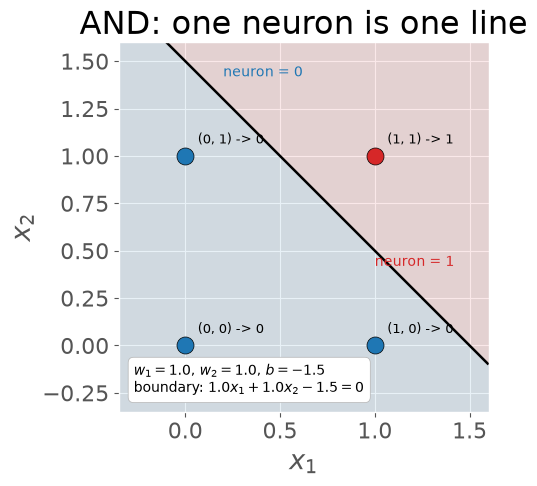

In [15]:
# The same neuron as a picture: the half-plane where it answers 1, and its boundary
g = np.linspace(-0.35, 1.6, 300)
g1, g2 = np.meshgrid(g, g)
score = w_and[0, 0] * g1 + w_and[1, 0] * g2 + b_and.item()

fig, ax = plt.subplots(figsize=(5.4, 4.8))
ax.contourf(g1, g2, score, levels=[score.min() - 1, 0], colors=["tab:blue"], alpha=0.10)
ax.contourf(g1, g2, score, levels=[0, score.max() + 1], colors=["tab:red"], alpha=0.10)
ax.contour(g1, g2, score, levels=[0], colors="black", linewidths=1.8)

for (x1, x2), t in zip(X_gates.tolist(), y_and.ravel().tolist()):
    ax.scatter(x1, x2, s=150, c="tab:red" if t else "tab:blue", edgecolor="black", zorder=3)
    ax.annotate(f"({x1:.0f}, {x2:.0f}) -> {t:.0f}", (x1, x2),
                textcoords="offset points", xytext=(9, 9), fontsize=9)

w1_and, w2_and, bias_and = w_and[0, 0].item(), w_and[1, 0].item(), b_and.item()
ax.text(1.42, 0.42, "neuron = 1", color="tab:red", fontsize=10, ha="right")
ax.text(0.20, 1.42, "neuron = 0", color="tab:blue", fontsize=10)
ax.text(0.04, 0.04, f"$w_1={w1_and:.1f}$, $w_2={w2_and:.1f}$, $b={bias_and:.1f}$\n"
        f"boundary: ${w1_and:.1f}x_1+{w2_and:.1f}x_2{bias_and:+.1f}=0$",
        transform=ax.transAxes, va="bottom", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="0.7"))

ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_xlim(-0.35, 1.6); ax.set_ylim(-0.35, 1.6)
ax.set_aspect("equal")
ax.set_title("AND: one neuron is one line");


هیچ آموزشی لازم نبود: با $w_1=w_2=1$ و $b=-1.5$ نرون فقط وقتی شلیک می‌کند که
$x_1+x_2>1.5$، و میان این چهار ورودی این تنها برای $(1,1)$ رخ می‌دهد. هندسی، نرون خط
$x_1+x_2=1.5$ را کشید و یک طرفش ۱ و طرف دیگر ۰ گفت. نمودار بالا دقیقاً همین را می‌کشد: نیم‌صفحهٔ
سایه‌دار جایی است که نرون ۱ می‌گوید، خط پُر مرز است، و جعبهٔ گوشه سه عددی را نگه می‌دارد که مرز را
می‌گذارند. پنل (a) شکل پایین‌تر همان خط را روی دادهٔ XOR نشان می‌دهد.

کلاس‌هایی را که یک خط می‌تواند جدا کند **جداپذیر خطی** می‌نامیم، و یک نرون یک دسته‌بند خطی است.

### یاد گرفتن وزن‌ها به‌جای چیدن آن‌ها

سهم روزنبلات نرون نبود، بلکه قاعده‌ای بود که $\mathbf w$ و $b$ را پیدا می‌کند — یک خط حساب، بدون
حسابان:

$$w_j \leftarrow w_j + \eta\,(y-\hat y)\,x_j, \qquad b \leftarrow b + \eta\,(y-\hat y)$$

سطری که نرون درست جواب می‌دهد هیچ چیز را تغییر نمی‌دهد؛ یک ۰ نادرست مرز را به سمت آن نقطه می‌کشد،
یک ۱ نادرست آن را دور می‌کند، و $\eta$ می‌گوید هر بار چقدر جابه‌جا شود. تا وقتی یک دور کامل بدون خطا
بگذرد تکرار کنید. این قاعده نیای هر به‌روزرسانی در این درس است.


In [16]:
def train_perceptron(X, y, eta=0.5, epochs=200):
    '''Rosenblatt's rule: nudge w and b after every mistake, stop when an epoch has none.'''
    w, b = torch.zeros(2, 1), torch.zeros(1)
    history = []
    for epoch in range(epochs):
        mistakes = 0
        for xi, yi in zip(X, y):
            p = step_neuron(xi.reshape(1, -1), w, b)
            if p != yi:                                  # only a mistake changes anything
                w = w + eta * (yi - p) * xi.reshape(-1, 1)
                b = b + eta * (yi - p)
                mistakes += 1
        history.append(mistakes)
        if mistakes == 0:
            break
    return w, b, history

w_learn, b_learn, mistakes_and = train_perceptron(X_gates, y_and)
print(f"learnt: w = ({w_learn[0,0]:.1f}, {w_learn[1,0]:.1f}), b = {b_learn.item():.1f}")
print(f"mistakes per epoch: {mistakes_and}  -> stopped after {len(mistakes_and)} epochs\n")
show_gate("AND", y_and, w_learn, b_learn)

learnt: w = (1.0, 0.5), b = -1.0
mistakes per epoch: [1, 3, 3, 2, 1, 0]  -> stopped after 6 epochs

AND   x1  x2 | target | neuron
     0   0 |   0    |   0
     0   1 |   0    |   0
     1   0 |   0    |   0
     1   1 |   1    |   1
     correct: 4 of 4



قاعده به‌محض اینکه یک دور کامل خطای صفر داشت ایستاد، و وزن‌هایی که پیدا کرد با وزن‌های
دستی متفاوت‌اند ولی خطی به‌همان خوبی را توصیف می‌کنند.

### همان جدول، به شکل یک دستگاه نامعادله

«این نرون کل جدول را جواب می‌دهد» وقتی نوشته شود، دستگاهی از شرط‌ها روی سه مجهول $w_1,w_2,b$ است.
برای AND، با سطرها به همان ترتیب بالا:

$$b\le 0,\qquad w_2+b\le 0,\qquad w_1+b\le 0,\qquad w_1+w_2+b>0$$

چهار شرط روی سه مجهول یک *ناحیهٔ* کامل در فضای $(w_1,w_2,b)$ جدا می‌کند و هر نقطهٔ آن یک نرون است که
AND را حل می‌کند. پس وزن‌ها هرگز یکتا نیستند: $(1,1,-1.5)$ و $(1,0.5,-1)$ هر دو کار می‌کنند، و
همچنین هر مضرب مثبتی از هرکدام. اینکه قاعده روی کدام نقطه می‌ایستد به ترتیب سطرها و به $\eta$ بستگی
دارد.

ناحیه یک مخروط است. هر چهار شرط همگن‌اند، پس اگر یک نقطه از آن جواب بدهد هر مضرب مثبتش هم جواب
می‌دهد، و مرزش هرمی است با رأس در مبدأ. برش آن در $b=-t$ مثلث $w_1\le t$، $w_2\le t$،
$w_1+w_2\ge t$ است، و مثلث با $t$ بزرگ می‌شود. شکل زیر بخشی از مخروط را که در
$0\le w_1,w_2\le 2$ و $-2\le b\le 0$ می‌افتد رسم می‌کند، که یک چهاروجهی است؛ هر دو جواب بالا
درون آن‌اند، روی وجه‌ها یا در درون.


(1, 1, -1.5):  b = -1.50 <= 0,  w2+b = -0.50 <= 0,  w1+b = -0.50 <= 0,  w1+w2+b = +0.50 > 0
(1, 0.5, -1):  b = -1.00 <= 0,  w2+b = -0.50 <= 0,  w1+b = +0.00 <= 0,  w1+w2+b = +0.50 > 0


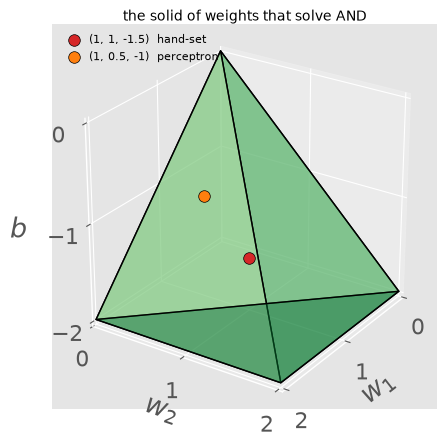

In [17]:
# Every point of this solid is a neuron that answers the AND table
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

for w1_, w2_, b_ in [(1.0, 1.0, -1.5), (1.0, 0.5, -1.0)]:
    print(f"({w1_:g}, {w2_:g}, {b_:g}):  b = {b_:+.2f} <= 0,  w2+b = {w2_ + b_:+.2f} <= 0,  "
          f"w1+b = {w1_ + b_:+.2f} <= 0,  w1+w2+b = {w1_ + w2_ + b_:+.2f} > 0")

# inside the box 0 <= w1, w2 <= 2 and -2 <= b <= 0 the region has four corners: the origin,
# where its three upper bounds meet, and the three corners of the slice b = -2
apex = (0, 0, 0)
base = [(0, 2, -2), (2, 0, -2), (2, 2, -2)]
faces = [[apex, base[0], base[1]], [apex, base[1], base[2]], [apex, base[0], base[2]], base]
shades = plt.cm.Greens([0.35, 0.5, 0.65, 0.85])

fig = plt.figure(figsize=(5.6, 5.0))
ax = fig.add_subplot(projection="3d")
ax.computed_zorder = False                      # so the two points stay visible
solid = Poly3DCollection(faces, facecolors=shades, edgecolor="black",
                         linewidths=1.0, alpha=0.5)
solid.set_zorder(1)
ax.add_collection3d(solid)
ax.scatter(1, 1, -1.5, s=70, color="tab:red", edgecolor="black", depthshade=False,
           label="(1, 1, -1.5)  hand-set", zorder=5)
ax.scatter(1, 0.5, -1.0, s=70, color="tab:orange", edgecolor="black", depthshade=False,
           label="(1, 0.5, -1)  perceptron", zorder=5)

ax.set_xlabel("$w_1$"); ax.set_ylabel("$w_2$"); ax.set_zlabel("$b$", labelpad=10)
ax.set_xlim(0, 2.05); ax.set_ylim(0, 2.05); ax.set_zlim(-2.05, 0.05)
ax.set_xticks([0, 1, 2]); ax.set_yticks([0, 1, 2]); ax.set_zticks([-2, -1, 0])
ax.set_box_aspect((1, 1, 1.0)); ax.view_init(elev=26, azim=34)
ax.legend(loc="upper left", frameon=False, fontsize=8, handletextpad=0.4)
ax.set_title("the solid of weights that solve AND", fontsize=10, pad=2);


### XOR: همان نرون، و هیچ جوابی

حالا **XOR** (یا انحصاری) را بگیرید: خروجی ۱ وقتی ورودی‌ها **متفاوت** باشند.

| $x_1$ | $x_2$ | XOR |
|:---:|:---:|:---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

این جدول با AND دقیقاً در یک سطر فرق دارد، و همان یک تغییر کشنده است: حالا ۱ها روی یک قطر مربع
نشسته‌اند و ۰ها روی قطر دیگر. همان قاعده را رویش اجرا کنید:


In [18]:
w_fail, b_fail, mistakes_xor = train_perceptron(X_gates, y_xor, epochs=500)
print(f"first ten epochs: {mistakes_xor[:10]}")
print(f"last ten epochs : {mistakes_xor[-10:]}")
print(f"epochs run: {len(mistakes_xor)}, and not one of them had zero mistakes\n")
show_gate("XOR", y_xor, w_fail, b_fail)

first ten epochs: [2, 3, 4, 4, 4, 4, 4, 4, 4, 4]
last ten epochs : [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
epochs run: 500, and not one of them had zero mistakes

XOR   x1  x2 | target | neuron
     0   0 |   0    |   1
     0   1 |   1    |   1
     1   0 |   1    |   0
     1   1 |   0    |   0
     correct: 2 of 4



هیچ‌وقت ایست نمی‌کند، و خطاهای هر دور کم نمی‌شود: در XOR قاعده مدام آخرین تصحیح خودش را
خنثی می‌کند، چون هر خطی که به آن می‌رسد از قبل یک نقطه را در طرف اشتباه دارد، و همان نقطه چیز بعدی
است که می‌بیند. این شبیه شکست *آموزش* است، اما چیز قوی‌تری درست است: **هیچ وزن‌هایی وجود ندارند**.
این را به‌عنوان ایمان قبول نکنید — همهٔ نرون‌ها را امتحان کنید، نه فقط آن‌هایی که به ذهن می‌رسند.
یک نرون پله‌ای کاملاً با جهت بردار عمود بر مرزش، $\theta$، و جابه‌جایی خط، $c$، توصیف می‌شود؛ پس هر
دو را جاروب کنید.


In [19]:
# Every step neuron is a straight line: sweep every direction and every offset
theta = np.linspace(0, 2 * np.pi, 361)
c = np.linspace(-2, 2, 801)
scores = (X_gates.t().numpy()[0][None, :, None] * np.cos(theta)[:, None, None]
          + X_gates.t().numpy()[1][None, :, None] * np.sin(theta)[:, None, None]
          - c[None, None, :])
acc = ((scores > 0).astype(int) == y_xor.numpy().ravel()[None, :, None]).mean(axis=1)

print(f"best accuracy of one neuron on XOR: {acc.max():.0%}")
# many lines tie; among them keep the one that stays furthest from every point,
# so that the boundary can be drawn unambiguously in the figure
margin = np.abs(scores).min(axis=1)
i, j = np.unravel_index(np.where(acc == acc.max(), margin, -1).argmax(), acc.shape)
w_best = torch.tensor([[np.cos(theta[i])], [np.sin(theta[i])]], dtype=torch.float32)
b_best = torch.tensor([-c[j]], dtype=torch.float32)
show_gate("XOR", y_xor, w_best, b_best)

best accuracy of one neuron on XOR: 75%
XOR   x1  x2 | target | neuron
     0   0 |   0    |   1
     0   1 |   1    |   1
     1   0 |   1    |   1
     1   1 |   0    |   0
     correct: 3 of 4



**۷۵٪ سقف است.** برنده همان خط AND است، $x_1+x_2=1.5$، با دو طرف عوض‌شده: به نصفی که
$(0,1)$ و $(1,0)$ را دارد ۱ می‌گوید و به گوشه‌ای که $(1,1)$ را دارد ۰. دقیقاً یک نقطه در طرف اشتباه
می‌افتد: همان $(0,0)$ که خط با دو ۱ تنها می‌گذارد. هر خط دیگری حداقل به همین بدی عمل می‌کند.

و این دربارهٔ آموزش یا مقدار اولیه نیست. فرض کنید $w_1,w_2,b$ای وجود داشته باشد که XOR را حل کند:

- سطر $(0,0)\mapsto 0$ می‌خواهد $b\le 0$؛
- سطرهای $(0,1)$ و $(1,0)\mapsto 1$ می‌خواهند $w_2+b>0$ و $w_1+b>0$، و جمع این دو می‌دهد
  $w_1+w_2+2b>0$؛
- اما سطر $(1,1)\mapsto 0$ می‌خواهد $w_1+w_2+b\le 0$، یعنی $w_1+w_2+2b\le b\le 0$ — یک تناقض.

هیچ وزن‌هایی وجود ندارند، پس هیچ مقدار آموزشی آن‌ها را پیدا نمی‌کند. این همان نتیجه‌ای است که
مینسکی و پاپرت در ۱۹۶۹ مشهور کردند و دلیل خاموشی پژوهش شبکه‌های عصبی برای یک دهه شد: یک نرون
**تنها**، هرقدر هم خوب آموزش ببیند، یک دسته‌بند خطی است.

![](img/xor.png)

- پنل (a): AND — یک خط تمام کار را می‌کند، ۴ از ۴.
- پنل (b): XOR با بهترین نرونی که همین حالا پیدا کردیم — همان خط با دو طرف عوض‌شده، ۳ از ۴.
- پنل (c): پاسخی که در بخش ۷ می‌سازیم — چهار نرون سیگموید پنهان که مرز ترکیبی‌شان دور دو ۱ خم
  می‌شود، ۴ از ۴.

همین آزمایش به هیچ کدی نیاز ندارد: [TensorFlow Playground](https://playground.tensorflow.org/#activation=linear&batchSize=10&dataset=xor&regDataset=reg-plane&learningRate=0.03&regularizationRate=0&noise=0&networkShape=1&seed=0.31848&showTestData=false&discretize=true&percTrainData=50&x=true&y=true&xTimesY=false&xSquared=false&ySquared=false&cosX=false&sinX=false&cosY=false&sinY=false&collectStats=false&problem=classification&initZero=false&hideText=false) تمام این بخش را زنده نشان می‌دهد:

- **یک نرون پنهان**، فعال‌سازی خطی، دادهٔ XOR، دکمهٔ پخش: مرز یک خط راست است و خطا در همان سطح
  ۳ از ۴ می‌ایستد.
- **سه یا چهار نرون پنهان**، سیگموید یا ReLU، دوباره پخش: مرز خم می‌شود و هر چهار گوشه درست
  می‌شوند. این همان کاری است که بخش ۷ در کد می‌کند.

راه خروج در ۱۹۶۹ هم معلوم بود: اگر یک خط کافی نیست، از **چند نرون** استفاده کنید و بگذارید یک لایهٔ
دوم خط‌هایشان را در مرزی که خم می‌شود ترکیب کند. آنچه کم بود راهی برای *آموزش* چنین شبکه‌ای بود —
قاعدهٔ پرسپترون نمی‌تواند، چون فعال‌سازی پله تقریباً همه‌جا مشتق صفر دارد. آن راه پس‌انتشار است، و
بخش بعدی است.


## ۶. پس‌انتشار

هر شبکه‌ای که تا اینجا برازش کردیم با همان تکه‌کد کوتاه آموزش دید، که داخل `trainer()` پنهان است:

```python
optimizer.zero_grad()        # 1. forget the gradients left by the previous batch
y_hat = model(X)             # 2. forward pass: compute the prediction
loss  = criterion(y_hat, y)  # 3. how wrong are we?
loss.backward()              # 4. backward pass: compute the gradients
optimizer.step()             # 5. move the parameters against the gradient
```

خط `loss.backward()` همان چیزی است که تا حالا مثل جعبهٔ سیاه با آن رفتار می‌کردیم. این
**پس‌انتشار** است: قاعدهٔ زنجیره‌ای، که به عقب و لایه‌به‌لایه روی شبکه اعمال می‌شود. حقه این است که
مشتق خطا نسبت به خروجی یک بار حساب می‌شود و بعد هر پارامتری که در آن خروجی سهیم بوده آن را
*دوباره استفاده* می‌کند؛ به همین دلیل هزینهٔ یک گذر رو به عقب تقریباً برابر یک گذر رو به جلوست.

برای دیدنش به‌طور مشخص، کوچک‌ترین شبکه‌ای را بردارید که هنوز غیرخطی است: یک ورودی، دو واحد پنهان
سیگموید، یک خروجی.

![](img/backprop-1.png)

### ۶.۱. گذر رو به جلو، دستی

وزن‌ها و بایاس‌ها را مثل شکل پایین ثابت کنید و یک مشاهدهٔ $x=1$ با هدف $y=3$ به شبکه بدهید:

![](img/backprop-3.png)

$$z_1=w_1x+b_1=2,\qquad a_1=\sigma(z_1)=0.88$$
$$z_2=w_2x+b_2=1,\qquad a_2=\sigma(z_2)=0.73$$
$$\hat y=w_3a_1+w_4a_2+b_3=1.34,\qquad \mathcal{L}=(\hat y-y)^2=2.75$$

هیچ چیز اینجا تازه نیست: یک لایهٔ خطی، یک سیگموید، یک لایهٔ خطی دیگر، و یک خطای مربعی، زنجیره‌وار.


### ۶.۲. گذر رو به عقب، دستی

از خطا شروع کنید و بپرسید وقتی $\hat y$ عوض شود $\mathcal{L}$ چقدر عوض می‌شود. برای خطای مربعی،

$$\frac{\partial\mathcal{L}}{\partial\hat y}=2(\hat y-y)=-3.31 .$$

همین یک عدد **گرادیان بالادستی** است. هر پارامتر پایین‌تر از آن گرادیان خودش را با ضرب گرادیان
بالادستی در مشتق **محلی** خودش می‌گیرد:

![](img/backprop-5.png)

$$\frac{\partial\mathcal{L}}{\partial w_3}
=\frac{\partial\mathcal{L}}{\partial\hat y}\,\frac{\partial\hat y}{\partial w_3}
=-3.31\times a_1=-2.92,\qquad
\frac{\partial\mathcal{L}}{\partial b_3}=-3.31$$

(شکل $-2.91$ چاپ می‌کند چون $a_1=0.8808$ را به $0.88$ گرد می‌کند)

برای لایهٔ پنهان به عقب‌رفتن را ادامه می‌دهیم. لایهٔ خروجی گرادیان نسبت به هر فعال‌سازی را پس
می‌دهد و سیگموید مشتق خودش را می‌آورد — همانی که در بخش ۲ استنتاج کردیم:

$$\frac{\partial\mathcal{L}}{\partial a_1}
=\frac{\partial\mathcal{L}}{\partial\hat y}\,w_3=-3.31,\qquad
\frac{\partial\mathcal{L}}{\partial z_1}
=\frac{\partial\mathcal{L}}{\partial a_1}\,\sigma'(z_1)=-3.31\times 0.105=-0.35$$

$$\frac{\partial\mathcal{L}}{\partial w_1}
=\frac{\partial\mathcal{L}}{\partial z_1}\,x=-0.35,\qquad
\frac{\partial\mathcal{L}}{\partial b_1}=\frac{\partial\mathcal{L}}{\partial z_1}=-0.35$$

همین دستور روی واحد پنهان دوم می‌دهد

$$\frac{\partial\mathcal{L}}{\partial a_2}=-6.62,\qquad
\frac{\partial\mathcal{L}}{\partial z_2}=-6.62\times 0.197=-1.30
\quad\Longrightarrow\quad
\frac{\partial\mathcal{L}}{\partial w_2}=\frac{\partial\mathcal{L}}{\partial b_2}=-1.30 .$$

![](img/backprop-7.png)

به دو چیزی توجه کنید که این کار را ارزان می‌کنند:

- شیء گران، $\partial\mathcal{L}/\partial\hat y$، **یک بار** حساب می‌شود و $w_3,w_4,b_3$ و هر دو
  واحد پنهان از آن استفاده می‌کنند.
- مشتق سیگموید فقط خروجی خودش را می‌خواهد: $\sigma'(z_1)=a_1(1-a_1)=0.88\times0.12=0.105$، بدون
  نمایی اضافی. این دقیقاً همان اتحادی است که در بخش ۲ ثابت شد، در حال استفاده.

عددی، با همان وزن‌ها:


In [20]:
x_bp, y_bp = torch.tensor([[1.0]]), torch.tensor([[3.0]])
w1, w2, b1, b2 = 1.0, -1.0, 1.0, 2.0
w3, w4, b3 = 1.0, 2.0, -1.0

z1, z2 = w1 * x_bp + b1, w2 * x_bp + b2
a1, a2 = torch.sigmoid(z1), torch.sigmoid(z2)
y_hat = w3 * a1 + w4 * a2 + b3
L = (y_hat - y_bp) ** 2

dL_dy = 2 * (y_hat - y_bp)                     # upstream gradient
dz1 = dL_dy * w3 * a1 * (1 - a1)             # through the output weight, then through the sigmoid
dz2 = dL_dy * w4 * a2 * (1 - a2)

print(f"z1={z1.item():.2f}  a1={a1.item():.3f}  sigma'(z1)={a1.item()*(1-a1.item()):.3f}")
print(f"z2={z2.item():.2f}  a2={a2.item():.3f}  sigma'(z2)={a2.item()*(1-a2.item()):.3f}")
print(f"y_hat={y_hat.item():.4f}  L={L.item():.3f}  dL/dy_hat={dL_dy.item():.2f}\n")
print("by hand:")
print(f"  dL/dw3={dL_dy.item()*a1.item():.2f}  dL/dw4={dL_dy.item()*a2.item():.2f}  dL/db3={dL_dy.item():.2f}")
print(f"  dL/dw1={dz1.item():.2f}  dL/db1={dz1.item():.2f}  dL/dw2={dz2.item():.2f}  dL/db2={dz2.item():.2f}")

z1=2.00  a1=0.881  sigma'(z1)=0.105
z2=1.00  a2=0.731  sigma'(z2)=0.197
y_hat=1.3429  L=2.746  dL/dy_hat=-3.31

by hand:
  dL/dw3=-2.92  dL/dw4=-2.42  dL/db3=-3.31
  dL/dw1=-0.35  dL/db1=-0.35  dL/dw2=-1.30  dL/db2=-1.30


### ۶.۳. همان گرادیان‌ها از PyTorch

شبکه را با دقیقاً همان وزن‌ها بسازید و بگذارید `backward()` حساب‌داری کند. اعداد پایین باید تا دو رقم
اعشار با حساب دستی یکی باشند — اگر باشند، جعبهٔ سیاه هیچ کاری نکرده که خودمان نکرده باشیم.


In [21]:
net = nn.Sequential(nn.Linear(1, 2), nn.Sigmoid(), nn.Linear(2, 1))
with torch.no_grad():                     # the weights of the figure, not random ones
    net[0].weight.copy_(torch.tensor([[w1], [w2]]))
    net[0].bias.copy_(torch.tensor([b1, b2]))
    net[2].weight.copy_(torch.tensor([[w3, w4]]))
    net[2].bias.copy_(torch.tensor([b3]))

loss = (net(x_bp) - y_bp) ** 2
loss.backward()

print(f"y_hat = {net(x_bp).item():.4f}, loss = {loss.item():.4f}")
for name, p in net.named_parameters():
    print(f"{name:10s}", [round(g, 2) for g in p.grad.flatten().tolist()])

y_hat = 1.3429, loss = 2.7459
0.weight   [-0.35, -1.3]
0.bias     [-0.35, -1.3]
2.weight   [-2.92, -2.42]
2.bias     [-3.31]


### ۶.۴. معنای این حرف برای `trainer()`

- **چرا گراف وجود دارد.** پارامترهایی که یک `nn.Module` می‌سازد با `requires_grad=True` می‌آیند، پس
  PyTorch هر عملیاتی که روی آن‌ها انجام شود ثبت می‌کند. چیز دیگری لازم نیست ردیابی شود: ما مشتق نسبت
  به پارامترها را می‌خواهیم، نه نسبت به داده.
- **`backward()` چه را پر می‌کند.** قبل از فراخوانی، `p.grad` برابر `None` است؛ بعد از آن
  $\partial\mathcal{L}/\partial p$ *برای همان دسته* را دارد. کل خروجی پس‌انتشار همین است.
- **چرا `zero_grad()` هست.** گرادیان‌ها به‌طور پیش‌فرض جمع می‌شوند. یک بار فراموشش کنید و دستهٔ بعد
  گرادیانش را به قبلی اضافه می‌کند، و نرخ یادگیری مؤثر جابه‌جا می‌شود.
- **`step()` چه می‌کند.** برای SGD ساده، $p\leftarrow p-\eta\,p.\mathrm{grad}$: دقیقاً همان
  به‌روزرسانی درس رگرسیون، که یک‌باره روی همهٔ پارامترها اعمال می‌شود.
- **پس‌انتشار بهینه‌ساز نیست.** فقط گرادیان حساب می‌کند؛ همان اعداد را می‌توان به SGD، Adam یا هر
  چیز دیگری داد.

یک نکتهٔ عملی: ما هرگز گرادیان را با تفاضل متناهی
$\big(f(w+h)-f(w-h)\big)/2h$ حساب نمی‌کنیم، هرچند ساده‌تر می‌بود. یک شبکه با $P$ پارامتر در هر گام
به $2P$ گذر رو به جلو نیاز داشت، در حالی که پس‌انتشار همهٔ $P$ مشتق را تقریباً به قیمت یک گذر رو به
جلو می‌دهد. (تمرین ۲ از شما می‌خواهد این دو را با هم مقایسه کنید — روی یک وزن، به‌عنوان بررسی.)


## ۷. شبکه‌ها در PyTorch

### ۷.۱. یک شبکه یک کلاس است

`nn.Sequential` برای مدل‌های بالا کافی است، اما معماری‌های واقعی کلاس می‌خواهند. هر مدل PyTorch از
`torch.nn.Module` ارث می‌برد، لایه‌هایش را در سازنده تعریف می‌کند، و در `forward()` می‌گوید چطور
زنجیره شوند.


In [22]:
class linearRegression(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()                                # inherit everything from nn.Module
        self.linear = nn.Linear(input_size, output_size)  # this is the whole model: wX + b

    def forward(self, x):
        return self.linear(x)


model = linearRegression(1, 1)
summary(model, (1,))
model.state_dict()

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                    [-1, 1]               2
Total params: 2
Trainable params: 2
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


OrderedDict([('linear.weight', tensor([[0.7083]])),
             ('linear.bias', tensor([0.6072]))])

In [23]:
sk = LinearRegression().fit(x_line.numpy(), y_line.numpy())
pd.DataFrame({"w0": [np.ravel(sk.intercept_)[0], model.linear.bias.item()],
              "w1": [np.ravel(sk.coef_)[0], model.linear.weight.item()]},
             index=["sklearn", "untrained pytorch"]).round(2)

,w0,w1
sklearn,1.03,1.93
untrained pytorch,0.61,0.71


آموزش‌ندیده، پارامترها تصادفی‌اند. هدف این تمرین شکل کد است، نه اعداد: `forward()` همان زنجیرهٔ
بخش ۱ است، و `nn.Sequential(a, b, c)` فقط کوتاه‌نوشت `c(b(a(x)))` است. شبکهٔ بخش ۴، با لایهٔ پنهانش
که صریح نوشته شده، یک `Sequential` داخل یک کلاس است:


In [24]:
class nonlinRegression(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(input_size, hidden_size),   # input  -> hidden layer
            nn.Sigmoid(),                         # the non-linearity, inside the hidden layer
            nn.Linear(hidden_size, output_size),  # hidden -> output layer
        )

    def forward(self, x):
        return self.main(x)


summary(nonlinRegression(1, 3, 1), (1,));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                    [-1, 3]               6
           Sigmoid-2                    [-1, 3]               0
            Linear-3                    [-1, 1]               4
Total params: 10
Trainable params: 10
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


### ۷.۲. پاداش XOR

بخش ۵ با یک وعده تمام شد: یک نرون حداکثر ۳ سطر از ۴ سطر XOR را درست می‌گیرد، و راه‌حل چند نرون در
یک لایهٔ پنهان است. همهٔ چیزی که لازم است حالا هست — `nn.Linear`، یک فعال‌سازی در لایهٔ پنهان، و
`trainer()` — پس وعده یک سلول فاصله دارد.

چهار نرون پنهان بیشتر از حداقل است (دو خط از قبل می‌توانند یک نوار بسازند)، اما با فقط چهار نقطهٔ
آموزشی شبکهٔ دو-نرونی اغلب همان‌جای بخش ۵ می‌ایستد؛ با چهار نرون از هر مقدار اولیهٔ معقولی به جواب
می‌رسد. نرون خروجی هم از یک سیگموید می‌گذرد، پس شبکه یک احتمال پیش‌بینی می‌کند و کلاس
«احتمال > 0.5» است.


In [25]:
X_xor = X_gates
y_xor_f = y_xor

torch.manual_seed(0)
xor_model = nn.Sequential(
    nn.Linear(2, 4),   # two inputs -> four hidden neurons
    nn.Sigmoid(),      # the non-linearity, in the hidden layer
    nn.Linear(4, 1),   # four hidden values -> one output neuron
    nn.Sigmoid(),      # output as a probability in (0, 1)
)
xor_loss = trainer(xor_model, nn.MSELoss(), torch.optim.Adam(xor_model.parameters(), lr=0.1),
                   X_xor, y_xor_f, epochs=500)

with torch.no_grad():
    p_xor = xor_model(X_xor).ravel()
print(f"final loss: {xor_loss:.5f}\n")
print("x1  x2 | XOR | probability | class")
for (x1, x2), t, p in zip(X_xor.tolist(), y_xor_f.ravel().tolist(), p_xor.tolist()):
    print(f" {x1:.0f}   {x2:.0f} |  {t:.0f}  |    {p:.3f}     |   {int(p > 0.5)}")
print(f"\naccuracy: {int(((p_xor > 0.5) == y_xor_f.ravel()).sum())} of 4")

final loss: 0.00018

x1  x2 | XOR | probability | class
 0   0 |  0  |    0.007     |   0
 0   1 |  1  |    0.995     |   1
 1   0 |  1  |    0.980     |   1
 1   1 |  0  |    0.017     |   0

accuracy: 4 of 4


۴ از ۴، و نه به‌سختی: احتمال‌ها نزدیک ۰ و ۱ هستند، پس خطای مربعی روی چهار سطر ناچیز است —
در برابر ۰.۲۵ بهترین نرون تنها، که یک سطر غلطش به‌تنهایی $\tfrac14$ می‌دهد. پنل (c) شکل XOR همان
مرز خمیده‌ای را نشان می‌دهد که این شبکه می‌کشد.

چه چیزی **عوض نشد**: خطا هنوز خطای مربعی است، بهینه‌ساز هنوز همان حلقهٔ پیش‌بینی–خطا–گرادیان–
به‌روزرسانی را اجرا می‌کند، و تنها جزء تازه سیگموید وسط است. یک غیرخطی‌بودن در لایهٔ پنهان همان چیزی
است که مدل خطی را به مرزی که می‌تواند خم شود تبدیل می‌کند.

یک هشدار صادقانه: با چهار نقطهٔ آموزشی این یک اسباب‌بازی است. نشان می‌دهد *چرا* لایهٔ پنهان لازم
است، نه اینکه یک شبکهٔ آموزش‌دیده همیشه جواب را پیدا می‌کند.

### ۷.۳. بازگشت به دادهٔ منحنی: نرون‌های پنهان چه می‌کنند

همان دستور روی دادهٔ رگرسیون غیرخطی بخش ۴، با سه نرون پنهان سیگموید (شبکهٔ پنل (a) بالا). اول،
مدل *خطی* چه می‌تواند بکند — هیچ، جز یک خط راست:


In [26]:
np.random.seed(2020)
X_nl = np.sort(np.random.randn(500))
y_nl = X_nl ** 2 + 15 * np.sin(X_nl) ** 3
X_nl_t = torch.tensor(X_nl[:, None], dtype=torch.float32)
y_nl_t = torch.tensor(y_nl[:, None], dtype=torch.float32)

torch.manual_seed(0)
linear_model = nn.Sequential(nn.Linear(1, 1))
loss_linear = trainer(linear_model, nn.MSELoss(), torch.optim.SGD(linear_model.parameters(), lr=0.3),
                      X_nl_t, y_nl_t, epochs=200)
print(f"loss of one linear neuron: {loss_linear:.4f}")

with torch.no_grad():
    p_linear = linear_model(X_nl_t).numpy().ravel()
plot_regression(X_nl, y_nl, p_linear, y_range=[-25, 25], dy=5);

loss of one linear neuron: 12.9659


هیچ نرخ یادگیری یا تعداد دوری بهتر نمی‌کند: آن خطا کوچک‌ترین خطای مربعی است که **هر** خطی
روی این داده می‌تواند برسد، همان برازش کمترین‌مربعات هفتهٔ قبل. حالا سه نرون پنهان سیگموید اضافه کنید:


In [27]:
torch.manual_seed(0)
nonlin_model = nonlinRegression(1, 3, 1)
loss_nonlin = trainer(nonlin_model, nn.MSELoss(), torch.optim.SGD(nonlin_model.parameters(), lr=0.3),
                      X_nl_t, y_nl_t, epochs=200)
print(f"loss with three hidden neurons: {loss_nonlin:.4f}")

with torch.no_grad():
    p_nonlin = nonlin_model(X_nl_t).numpy().ravel()
plot_regression(X_nl, y_nl, p_nonlin, y_range=[-25, 25], dy=5);

loss with three hidden neurons: 4.0348


دو عددی را که بالا چاپ شد مقایسه کنید. منحنی بی‌نقص نیست، اما نکته *شکل* است: مدل حالا
می‌تواند بپیچد. هر نرون پنهان یک سیگموید به جمع می‌دهد

$$\hat y = \sum_{j=1}^{3} w^{(2)}_j\,\sigma\big(w^{(1)}_j x+b^{(1)}_j\big)+b^{(2)},$$

و شکل پایین این سهم‌ها را جدا می‌کند، با لغزنده‌ای که آن‌ها را یکی‌یکی جمع می‌کند. این مفیدترین تصویر
درس است: **لایهٔ پنهان ویژگی‌های غیرخطی می‌سازد، و لایهٔ خروجی یک مدل خطی روی آن‌ها برازش می‌کند.**


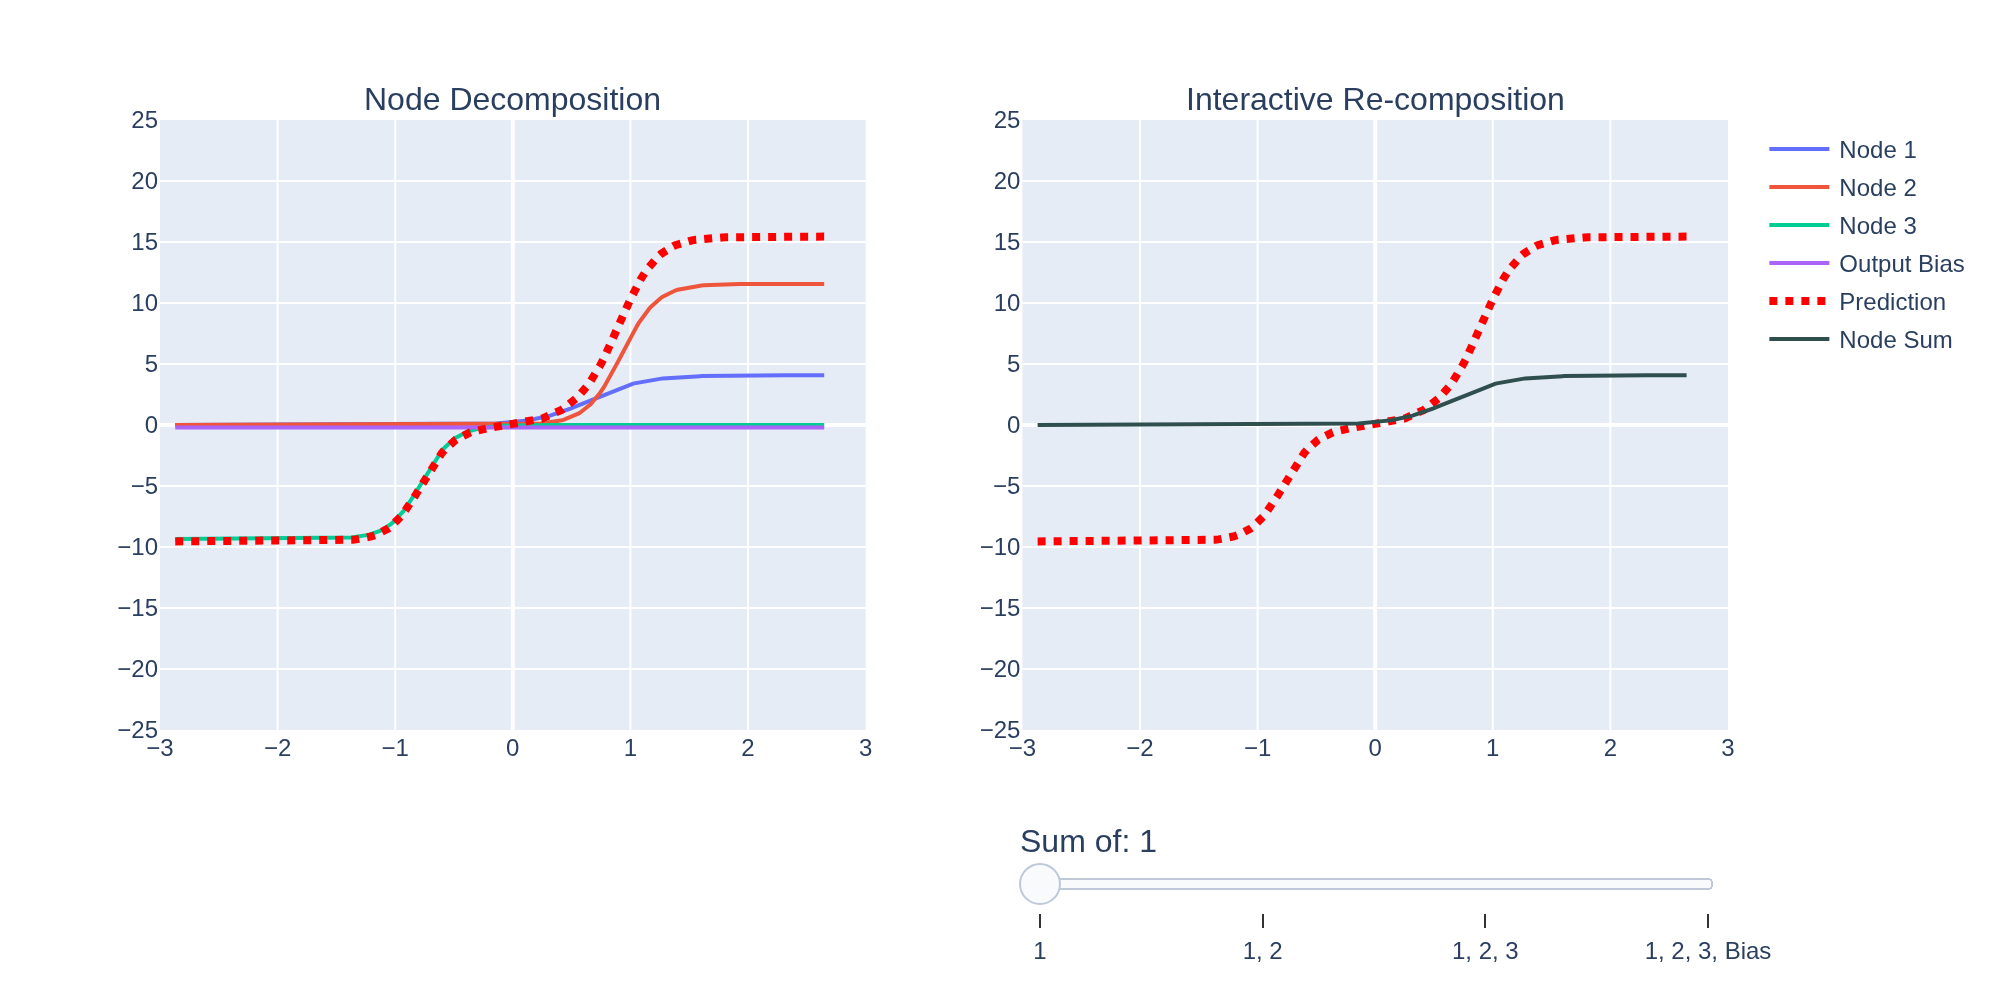

In [28]:
plot_nodes(X_nl, p_nonlin, nonlin_model, x_range=[-3, 3], y_range=[-25, 25], dy=5)

## ۸. توابع فعال‌سازی

سیگموید یکی از گزینه‌های بسیار است. PyTorch فعال‌سازی‌های رایج را به‌صورت لایه دارد، پس عوض‌کردن
فعال‌سازی یک ویرایش یک‌کلمه‌ای در `forward()` است:


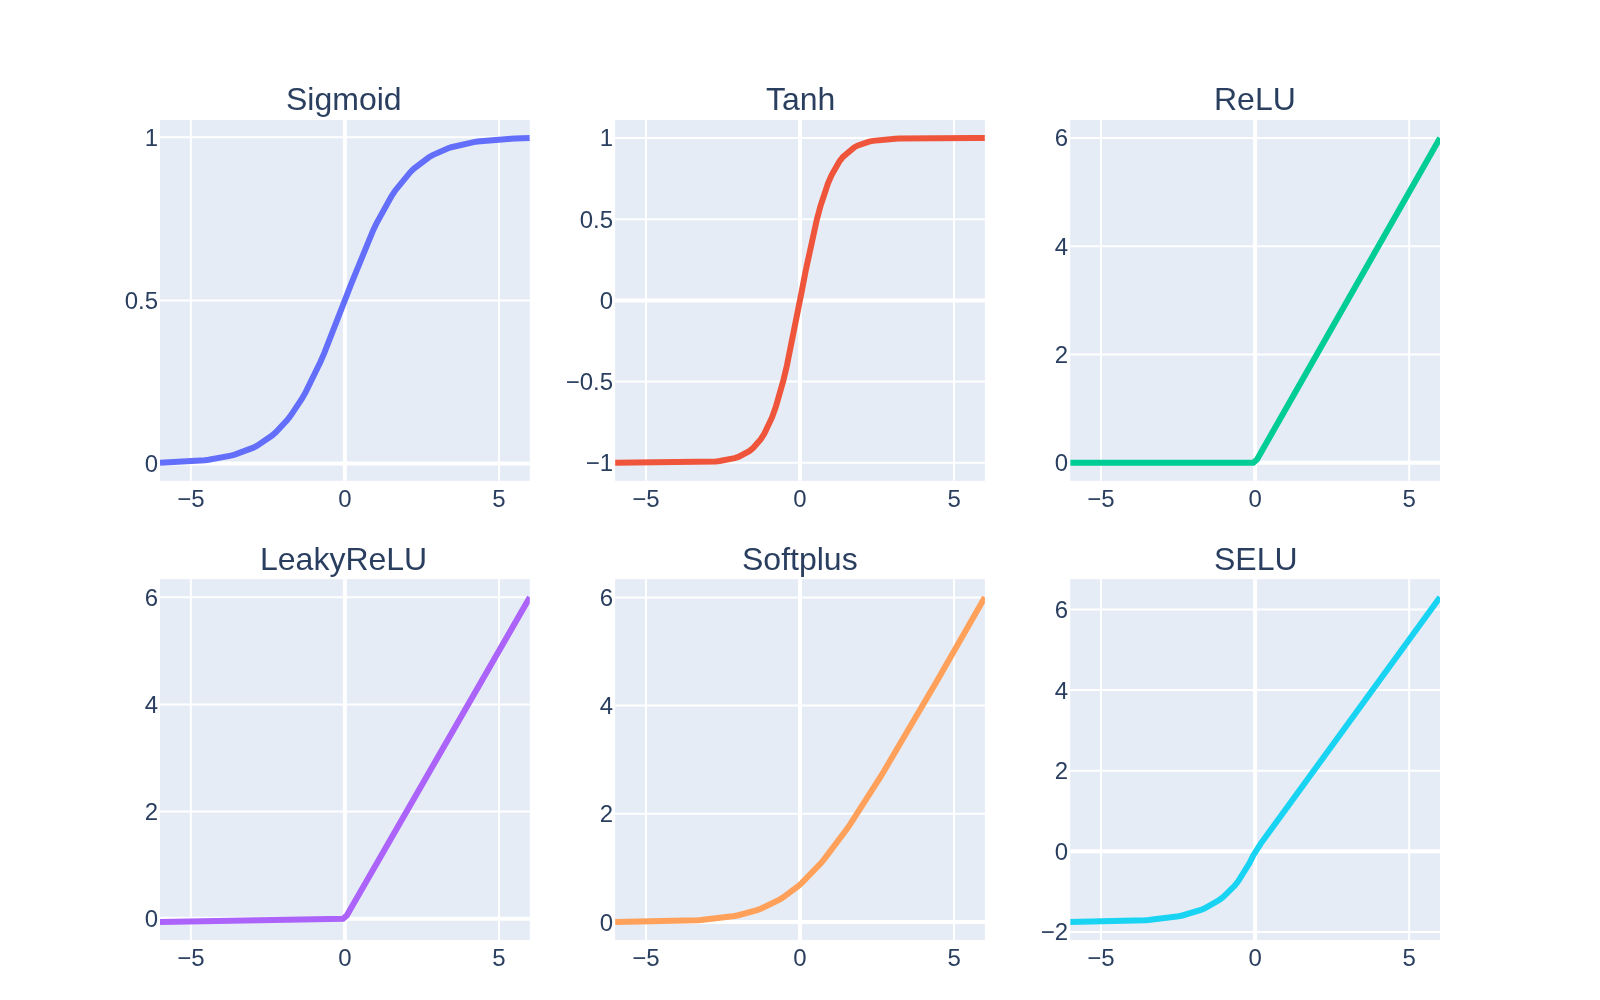

In [29]:
functions = [nn.Sigmoid, nn.Tanh, nn.ReLU, nn.LeakyReLU, nn.Softplus, nn.SELU]
plot_activations(torch.linspace(-6, 6, 100), functions)

آنچه برای آموزش مهم است مشتق است، و فعال‌سازی‌ها بیشتر در رفتارشان دور از صفر فرق
می‌کنند:

- **سیگموید / Tanh.** هموار و کران‌دار، اما اشباع‌شونده: مشتق به صفر می‌رود، پس پشته‌های عمیقشان
  خیلی کند یاد می‌گیرند (محو شدن گرادیان بخش ۲).
- **ReLU** یعنی $\max(0,z)$: مشتق برای $z>0$ برابر ۱ و پایین‌تر ۰ است، پس در سمت مثبت هرگز اشباع
  نمی‌شود، و ارزان است. ضعفش این است که نرونی که در $z<0$ گیر کرده هیچ گرادیانی نمی‌گیرد — همان
  چیزی که LeakyReLU و SELU وصله‌اش می‌کنند.
- ReLU در ۰ مشتق‌پذیر نیست و `torch` سادگی یک زیرگرادیان را برمی‌دارد. در عمل کافی است.

> «...یکی از بزرگ‌ترین اشتباهاتی که کردم این بود که مثل همه در دههٔ ۹۰ فکر می‌کردم برای اینکه
> پس‌انتشار کار کند به غیرخطی‌های هموار نیاز داریم... اما در پایان معلوم شد که ReLU واقعاً خیلی بهتر
> از سیگمویدها و tanh کار می‌کرد، و این غافلگیری بزرگی بود.»
> — یوشوا بنژیو

**ReLU امروز در عمل پیش‌فرض است**، اما با فعال‌سازی مثل یک ابرپارامتر رفتار کنید.

### چرا غیرخطی‌بودن اختیاری نیست

فعال‌سازی‌ها را بردارید و روی‌هم‌چیدن لایه‌ها هیچ چیزی نمی‌خرد:

$$W_2\left(W_1x+b_1\right)+b_2=\left(W_2W_1\right)x+\left(W_2b_1+b_2\right)$$

دو لایهٔ خطی پشت سر هم *یک* لایهٔ خطی‌اند. عددی:


In [30]:
layer_1, layer_2 = nn.Linear(1, 3), nn.Linear(3, 1)
z = torch.tensor([[-3.0], [0.5], [2.0]])
torch.allclose(
    layer_2(layer_1(z)),
    z @ (layer_2.weight @ layer_1.weight).T + (layer_2.weight @ layer_1.bias + layer_2.bias),
)

True

پس عمق بدون فعال‌سازی، نوشتنِ گران‌تر `Linear(1, 1)` است. بخش ۷.۳ کار کرد چون یک سیگموید
بین دو لایهٔ خطی نشسته بود؛ همین است که ترکیب را خم می‌کند.

### عمق: یک MLP

یک **MLP** (پرسپترون چندلایه) به‌سادگی شبکه‌ای با بیش از یک لایهٔ پنهان است:


In [31]:
class MLP(nn.Module):
    def __init__(self, input_size, hidden_1, hidden_2, output_size):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(input_size, hidden_1), nn.Sigmoid(),
            nn.Linear(hidden_1, hidden_2), nn.Sigmoid(),
            nn.Linear(hidden_2, output_size),
        )

    def forward(self, x):
        return self.main(x)


torch.manual_seed(0)
mlp = MLP(1, 5, 3, 1)
loss_mlp = trainer(mlp, nn.MSELoss(), torch.optim.SGD(mlp.parameters(), lr=0.3),
                   X_nl_t, y_nl_t, epochs=200)
print(f"loss of the 2-hidden-layer MLP: {loss_mlp:.4f}")
with torch.no_grad():
    p_mlp = mlp(X_nl_t).numpy().ravel()
plot_regression(X_nl, y_nl, p_mlp, y_range=[-25, 25], dy=5);

loss of the 2-hidden-layer MLP: 4.3002


با شبکهٔ تک‌لایهٔ سه‌نرونی بخش ۷.۳ مقایسه کنید: **لایه‌های بیشتر به‌طور خودکار برازش بهتر
نمی‌دهند.** عمق وقتی کمک می‌کند که تابع ساختار ترکیبی داشته باشد؛ روی یک منحنی هموار یک‌بعدی، پهنای
یک لایهٔ پنهان معمولاً کافی است. معماری — تعداد لایه‌ها، نرون‌های هر لایه، فعال‌سازی — یک ابرپارامتر
است که با اعتبارسنجی انتخاب می‌شود، دقیقاً مثل درس‌های قبل.


## ۹. دسته‌بندی با شبکه‌ها

ساده‌ترین بخش درس، چون همه‌چیز از قبل سر جایش است: یک شبکهٔ دسته‌بندی همان نرون سیگموید بخش ۳ است
که یک لایهٔ پنهان جلویش نشسته، دقیقاً مثل بخش ۷.۲.

مجموعه‌داده دو دایرهٔ هم‌مرکز است: دیسک درونی کلاس ۱ و حلقهٔ بیرونی کلاس ۰. هیچ خط راستی آن‌ها را جدا
نمی‌کند، که همان وضعیت XOR با شکلی واقعی‌تر است.


In [32]:
X_c, y_c = make_circles(n_samples=300, factor=0.5, noise=0.1, random_state=2020)
plot_classification_2d(X_c, y_c);

یک دسته‌بند خطی فقط می‌تواند خطی از این میان بکشد، پس دارد حدس می‌زند:


In [33]:
from sklearn.linear_model import LogisticRegression
print(f"accuracy of logistic regression: {LogisticRegression().fit(X_c, y_c).score(X_c, y_c):.0%}")

accuracy of logistic regression: 51%


یک لایهٔ پنهان با هشت نرون ReLU، و بعد یک نرون خروجی. دو تغییر نسبت به شبکه‌های رگرسیون:

- خطا **آنتروپی متقاطع دودویی** (خطای لگاریتمی) است، خطای درست برای احتمال‌ها
  $$f(\mathbf w)=-\sum_{i}\Big[y_i\log\hat y_i+(1-y_i)\log(1-\hat y_i)\Big];$$
- لایهٔ خروجی **سیگموید ندارد**، و از `BCEWithLogitsLoss` استفاده می‌کنیم که سیگموید و لگاریتم را
  یک‌جا و به‌شکلی پایدار عددی اعمال می‌کند. پس مدل یک *لجیت* می‌دهد — هر عدد حقیقی — و سیگموید فقط
  وقتی اعمال می‌شود که احتمال بخواهیم.


final loss: 0.0074, training accuracy: 100%


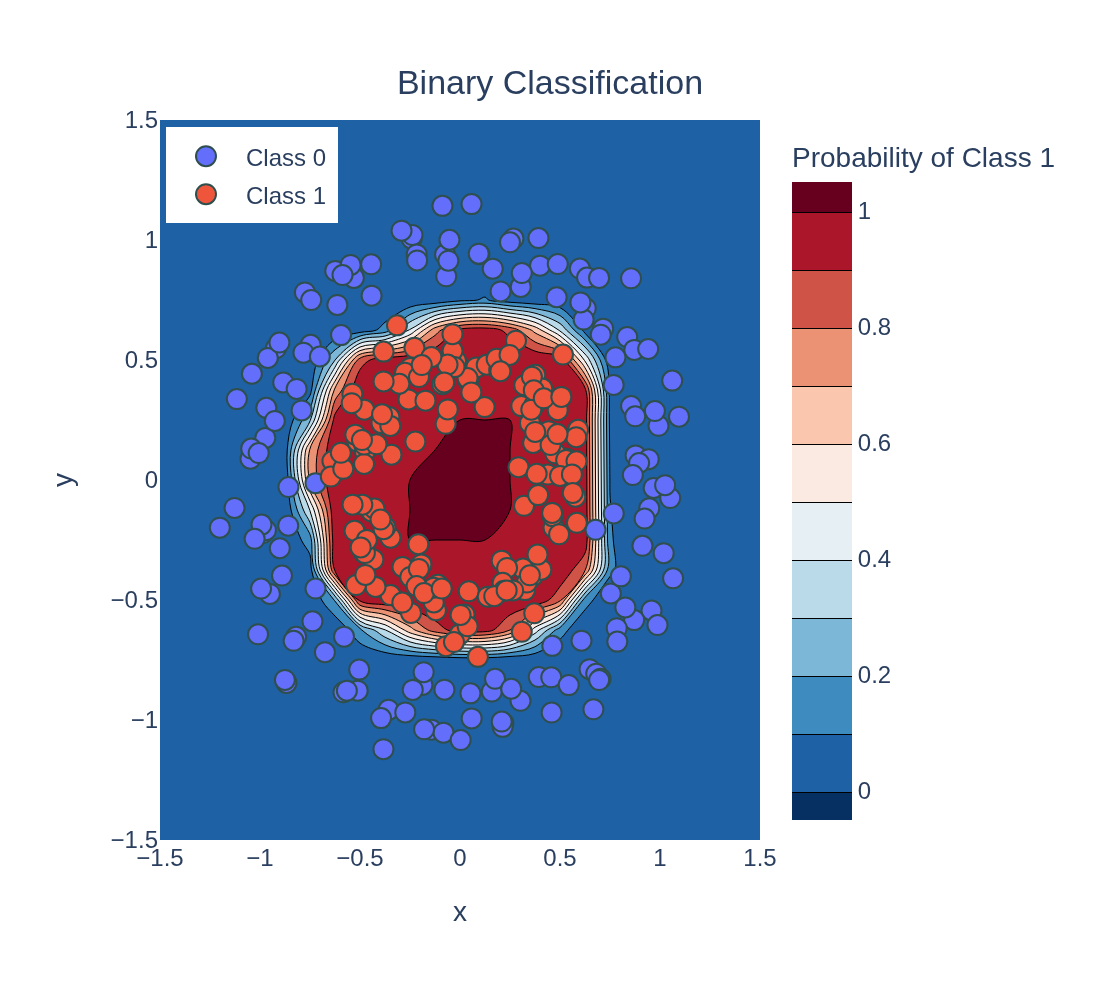

In [34]:
class binaryClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.main = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, output_size),   # no sigmoid: BCEWithLogitsLoss includes it
        )

    def forward(self, x):
        return self.main(x)


X_c_t = torch.tensor(X_c, dtype=torch.float32)
y_c_t = torch.tensor(y_c, dtype=torch.float32).reshape(-1, 1)

torch.manual_seed(0)
clf = binaryClassifier(2, 8, 1)
clf_loss = trainer(clf, nn.BCEWithLogitsLoss(), torch.optim.Adam(clf.parameters(), lr=0.05),
                   X_c_t, y_c_t, epochs=100, batch_size=50)
accuracy = (((clf(X_c_t) > 0).float() == y_c_t).float().mean().item())
print(f"final loss: {clf_loss:.4f}, training accuracy: {accuracy:.0%}")
plot_classification_2d(X_c, y_c, clf)

مرز دیگر خط نیست: دور دیسک درونی بسته می‌شود. `ReLU` و `Adam` اینجا استفاده شده‌اند چون
پیش‌فرض‌های امروزند؛ حلقه تغییری نکرده.

مدل لجیت می‌دهد، پس برای گرفتن احتمال‌ها و کلاس‌ها خودمان سیگموید را اعمال می‌کنیم — همان زنجیرهٔ
یک‌خطی بخش ۳:


In [35]:
points = torch.tensor([[0.0, 0.0], [-1.0, -1.0], [0.6, 0.0]])
logits = clf(points).detach().ravel()
probabilities = torch.sigmoid(logits)
print("logits       :", [round(v, 2) for v in logits.tolist()])
print("probabilities:", [round(v, 3) for v in probabilities.tolist()])
print("classes      :", (probabilities > 0.5).int().tolist())

logits       : [25.07, -28.8, 3.66]
probabilities: [1.0, 0.0, 0.975]
classes      : [1, 0, 1]


### دسته‌بندی چندکلاسه (اختیاری، اگر وقت بود)

برای $K$ کلاس، لایهٔ خروجی $K$ نرون دارد و فشرده‌ساز **softmax** است، که $K$ لجیت را به $K$ احتمال
که جمعشان ۱ است تبدیل می‌کند:

$$\mathrm{softmax}(\mathbf z)_i=\frac{e^{z_i}}{\sum_{j=1}^{K}e^{z_j}}$$

`nn.CrossEntropyLoss` سافت‌مکس را با آنتروپی متقاطع ترکیب می‌کند، پس شبکه دوباره به یک لایهٔ خطی
خالی ختم می‌شود.


final loss: 0.0007


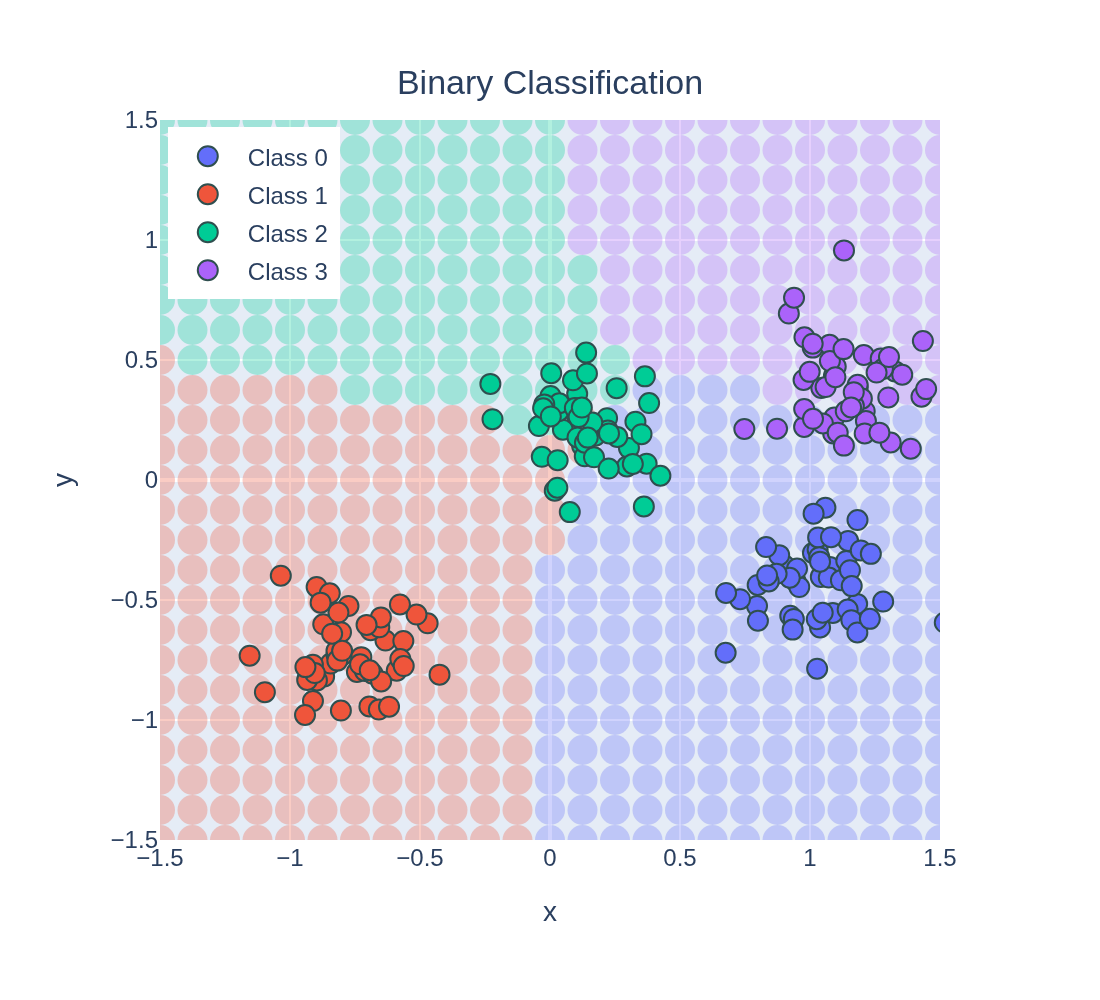

In [36]:
X_m, y_m = make_blobs(n_samples=200, centers=4, center_box=(-1.2, 1.2),
                       cluster_std=0.15, random_state=12345)

torch.manual_seed(0)
multi = nn.Sequential(nn.Linear(2, 10), nn.ReLU(), nn.Linear(10, 4))
multi_loss = trainer(multi, nn.CrossEntropyLoss(), torch.optim.Adam(multi.parameters(), lr=0.05),
                     torch.tensor(X_m, dtype=torch.float32),
                     torch.tensor(y_m, dtype=torch.long), epochs=100, batch_size=50)
print(f"final loss: {multi_loss:.4f}")

plot_classification_2d(X_m, y_m, multi, transform="Softmax")

In [37]:
logits = multi(torch.tensor([[-1.0, -1.0], [0.0, 0.0]])).detach()
print("logits :", logits.tolist())
print("softmax:", nn.Softmax(dim=1)(logits).round(decimals=3).tolist())
print("classes:", logits.argmax(dim=1).tolist())

logits : [[-10.705239295959473, 13.748056411743164, -2.231656312942505, -27.679887771606445], [-8.243534088134766, -0.6005109548568726, 8.306304931640625, -8.829578399658203]]
softmax: [[0.0, 1.0, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0]]
classes: [1, 2]


به خوانش دو مرحله‌ای خروجی توجه کنید، مثل حالت دودویی: اول لجیت‌ها (آنچه شبکه حساب می‌کند)،
بعد `softmax` برای احتمال‌ها، و بعد `argmax` برای کلاس.


## ۱۰. کل درس در یک صفحه

1. **یک نرون** یک مدل خطی به‌علاوهٔ یک فعال‌سازی است: $a=\varphi(\mathbf w^\top\mathbf x+b)$. با همانی
   می‌شود رگرسیون خطی؛ با سیگموید، رگرسیون لجستیک؛ با پله، پرسپترون.
2. **سیگموید** فعال‌سازی‌ای است که یک امتیاز را به احتمال تبدیل می‌کند، و مشتقش وقتی خروجی معلوم باشد
   مجانی است: $\sigma'(z)=\sigma(z)(1-\sigma(z))$. همان چیزی که آموزش گرادیانی یک نرون *غیرخطی* را
   ممکن کرد.
3. **یک نرون یک خط است.** AND را حل می‌کند و XOR را نه، به دلیلی که می‌توان ثابت کرد نه فقط مشاهده.
   اضافه‌کردن نرون‌ها کنار هم، در یک لایهٔ پنهان، همان چیزی است که مرز و منحنی را خم می‌کند.
4. **پس‌انتشار** قاعدهٔ زنجیره‌ای است که به عقب اعمال می‌شود و گرادیان بالادستی را در هر انشعاب دوباره
   به کار می‌برد. `loss.backward()` همان محاسبه است و نه چیزی بیشتر؛ `optimizer.step()` همان گرادیان
   کاهشی درس قبل است.
5. **بقیهٔ ماجرا معماری است**: چند لایه، چند نرون، کدام فعال‌سازی، کدام تابع خطا — ابرپارامترهایی که
   با اعتبارسنجی انتخاب می‌شوند، در حالی که حلقهٔ آموزش همان چهار خط می‌ماند.


## درست / نادرست

پیش از خواندن پاسخ‌ها جواب دهید:

1. شبکه‌های عصبی هم برای رگرسیون و هم برای دسته‌بندی به کار می‌روند. (**درست**)
2. در شبکه‌های عصبی کاملاً متصل، تعداد پارامترها $\geq$ تعداد ویژگی‌ها است. (**درست**)
3. شبکه‌های عصبی مدل‌های پارامتری‌اند. (**درست**)
4. هر شبکهٔ عصبی با ۳ لایهٔ پنهان از هر شبکه‌ای با ۲ لایهٔ پنهان پارامتر بیشتری دارد. (**نادرست** —
   پهنا مهم‌تر از عمق است)
5. معماری یک شبکهٔ عصبی (تعداد لایه‌های پنهان و گره‌های پنهان) یک ابرپارامتر است. (**درست**)
6. مثل رگرسیون خطی، هر وزن یک شبکهٔ آموزش‌دیده را می‌توان اهمیت ویژگی‌اش خواند. (**نادرست**)
7. یک شبکه با دو لایهٔ خطی و بدون فعال‌سازی معادل یک لایهٔ خطی است. (**درست**)
8. پس‌انتشار یک الگوریتم یادگیری است. (**نادرست** — گرادیان حساب می‌کند؛ یادگیری کار بهینه‌ساز است)


## تمرین‌ها

1. **استنتاج و بررسی.** رابطهٔ $\tanh'(z)=1-\tanh^2(z)$ را استنتاج کنید، سپس هم این و هم
   $\sigma'(z)=\sigma(z)(1-\sigma(z))$ را عددی روی یک شبکه با `torch.autograd` بررسی کنید.
2. **بررسی گرادیان.** شبکهٔ بخش ۶ را با همان وزن‌های ثابت و یک ورودی بردارید. گرادیان تحلیلی
   $\partial\mathcal{L}/\partial w_1$ را با تفاضل مرکزی
   $\big(\mathcal{L}(w_1+h)-\mathcal{L}(w_1-h)\big)/2h$ برای $h=10^{-12},\dots,10^{-1}$ مقایسه کنید.
   خطای نسبی را برحسب $h$ رسم کنید و شکل U را توضیح دهید (خطای برش از یک طرف، خطای گردکردن از طرف
   دیگر).
3. **نرون بیشتر، نوسان بیشتر.** برآمدگی بخش ۴ را با سه نرون پنهان به‌جای دو نرون برازش کنید. مدل
   چند نوسان می‌تواند بسازد؟ بعد داده‌ای با دو برآمدگی بسازید و برازش کنید؛ چند نرون لازم دارید؟
4. **عمق بدون غیرخطی‌بودن.** فعال‌سازی لایهٔ پنهان بخش ۷.۳ را با همانی عوض کنید، دوباره آموزش دهید،
   و خطای نهایی را گزارش کنید. فروپاشی چه ویژگی‌ای از شبکه را نشان می‌دهد؟
5. **XOR و شانس.** شبکهٔ XOR بخش ۷.۲ را با دو نرون پنهان و روی ۲۰ بذر مختلف آموزش دهید و بشمارید
   چند بار به ۴ از ۴ می‌رسد. شکست‌ها را با هندسهٔ بخش ۵ توضیح دهید.
6. **توابع خطا.** آزمایش XOR را با `BCEWithLogitsLoss` به‌جای `MSELoss` تکرار کنید و مقایسه کنید
   پیش‌بینی‌ها چقدر مطمئن‌تر می‌شوند. کدام خطا یک اشتباه مطمئن را بیشتر تنبیه می‌کند؟


## مطالعهٔ بیشتر

- [TensorFlow Playground](https://playground.tensorflow.org/) — نسخهٔ تعاملی بخش‌های ۵ و ۷؛ سریع‌ترین
  راه ساختن شهود دربارهٔ لایه‌های پنهان و مرزهای تصمیم.
- Dive into Deep Learning، [فصل پرسپترون‌های چندلایه](https://d2l.ai/chapter_multilayer-perceptrons/index.html)
  و [فصل بهینه‌سازی](https://d2l.ai/chapter_optimization/index.html).
- Rosenblatt, F. (1958). *The perceptron: a probabilistic model for information storage and organization
  in the brain.* Psychological Review 65(6).
- Minsky, M. & Papert, S. (1969). *Perceptrons: An Introduction to Computational Geometry.* MIT Press.
- Rumelhart, D., Hinton, G. & Williams, R. (1986). *Learning representations by back-propagating errors.*
  Nature 323.
